Academic Integrity and Learning Statement

By submitting my work, I confirm that:

1. The code, analysis, and documentation in this notebook are my own work and reflect my own understanding.
2. I am prepared to explain all code and analysis included in this submission.

If I used assistance (e.g., AI tools, tutors, or other resources), I have:

- Clearly documented where and how external tools or resources were used in my solution.
- Included a copy of the interaction (e.g., AI conversation or tutoring notes) in an appendix.

I acknowledge that:

- I may be asked to explain any part of my code or analysis during evaluation.
- Misrepresenting assisted work as my own constitutes academic dishonesty and undermines my learning.


In [1]:
# Import all librairies
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
import random
import missingno as msno
from scipy import stats

%matplotlib inline

Before I start I like to upload all my libraries at the top of the page so I wouldn't forget them later and also to be able to see clearly what i'm using and what i needed in the project.

# Task A: An overview of the dataset

1. **Import the data as a pandas DataFrame into the notebook:**

In [2]:
df = pd.read_pickle("data_385k.pkl", compression="zip") # Load the dataset

2. **Check the number of rows and columns:**

In [3]:
df.shape

(385384, 99)

3. **Display a few entries from the DataFrame:**

In [4]:
df.head(7)

,alcohol_by_volume,barcode,calcium_per_hundred,calcium_unit,carbohydrates_per_hundred,carbohydrates_per_portion,carbohydrates_unit,cholesterol_per_hundred,cholesterol_unit,copper_cu_per_hundred,...,vitamin_b5_panthothenic_acid_per_hundred,vitamin_b5_panthothenic_acid_unit,vitamin_b6_pyridoxin_per_hundred,vitamin_b6_pyridoxin_unit,vitamin_c_ascorbic_acid_per_hundred,vitamin_c_ascorbic_acid_unit,vitamin_d_d2_d3_international_units_per_hundred,vitamin_d_d2_d3_international_units_unit,zinc_per_hundred,zinc_unit
0,0.0,8001772000030,NaN,NaN,75.00,37.50,g,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,0.0,7610809001066,NaN,NaN,1.50,1.13,g,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,0.0,8002530159021,NaN,NaN,52.68,NaN,g,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,0.0,3033715065788,NaN,NaN,70.40,11.97,g,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,0.0,7610848492740,NaN,NaN,37.00,7.40,g,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
5,0.0,7610100033247,NaN,NaN,11.10,1.90,g,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
6,0.0,76145513,NaN,NaN,60.50,15.00,g,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


4. **Check the data type for each column:**

In [5]:
df.dtypes

alcohol_by_volume                                  float64
barcode                                             object
calcium_per_hundred                                float64
calcium_unit                                        object
carbohydrates_per_hundred                          float64
                                                    ...   
vitamin_c_ascorbic_acid_unit                        object
vitamin_d_d2_d3_international_units_per_hundred    float64
vitamin_d_d2_d3_international_units_unit            object
zinc_per_hundred                                   float64
zinc_unit                                           object
Length: 99, dtype: object

In [6]:
objects=df.select_dtypes("object").columns.tolist()
floats=df.select_dtypes("float64").columns.tolist()
ints=df.select_dtypes("int64").columns.tolist()

5. **Check the data by the type of information:**

In [7]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 385384 entries, 0 to 385383
Data columns (total 99 columns):
 #   Column                                           Non-Null Count   Dtype  
---  ------                                           --------------   -----  
 0   alcohol_by_volume                                385384 non-null  float64
 1   barcode                                          385384 non-null  object 
 2   calcium_per_hundred                              264979 non-null  float64
 3   calcium_unit                                     265086 non-null  object 
 4   carbohydrates_per_hundred                        351551 non-null  float64
 5   carbohydrates_per_portion                        11480 non-null   float64
 6   carbohydrates_unit                               351828 non-null  object 
 7   cholesterol_per_hundred                          270282 non-null  float64
 8   cholesterol_unit                                 270329 non-null  object 
 9   copper_cu_per_h

In [8]:
A = df.filter(regex="_per_hundred$", axis=1).copy()
B = df.filter(regex="_per_portion$", axis=1).copy()
C = df.filter(regex="_unit$", axis=1).copy()
list_drop = A.columns.tolist() + B.columns.tolist() + C.columns.tolist()
other_cols = df.copy()
other_cols = other_cols.drop(columns=list_drop)

# Task B: Data Cleaning

1. **Duplicated products in the data:**

In [9]:
df.duplicated()

0         False
1         False
2         False
3         False
4         False
          ...  
385379     True
385380     True
385381     True
385382     True
385383     True
Length: 385384, dtype: bool

In [10]:
df.duplicated().sum()

10500

There is 10500 duplicates.

I don't think all the duplcated values should be dropped. For example, units. However ID which is supposed to be unique for the product must not have duplicates which means we can drop it.

In [11]:
df.drop_duplicates(["id"], inplace=True)

In [12]:
df.duplicated(["id"]).sum()

0

The shape of the remaining data:

In [13]:
df.shape

(374884, 99)

2. **This data set contains a lot of missing values. Let’s find out where they are:**

   a. **Table of both the number and the percentage of missing values for all columns sorted from largest to smallest:**

In [14]:
missing_value_percentage= (df.isnull().sum()/ len(df)) *100 
missing_value_count = df.isnull().sum()
missing_value = pd.DataFrame ({"number of missing values": missing_value_count, "percentage of missing values": missing_value_percentage})
pd.set_option("display.max_rows", 100)
missing_value.sort_values(by="percentage of missing values", ascending=False)

,number of missing values,percentage of missing values
sodium_per_portion,374131,99.799138
fiber_insoluble_per_hundred,371375,99.063977
fiber_insoluble_unit,371374,99.063710
manganese_mn_per_hundred,371350,99.057308
manganese_mn_unit,371347,99.056508
copper_cu_per_hundred,371273,99.036769
copper_cu_unit,371273,99.036769
fiber_soluble_per_hundred,371057,98.979151
fiber_soluble_unit,371055,98.978617
folic_acid_per_hundred,370428,98.811366


   b. **Visualize where the missing are in the whole data frame and when missing values overlap between columns or not: (using missingno)**

<AxesSubplot:>

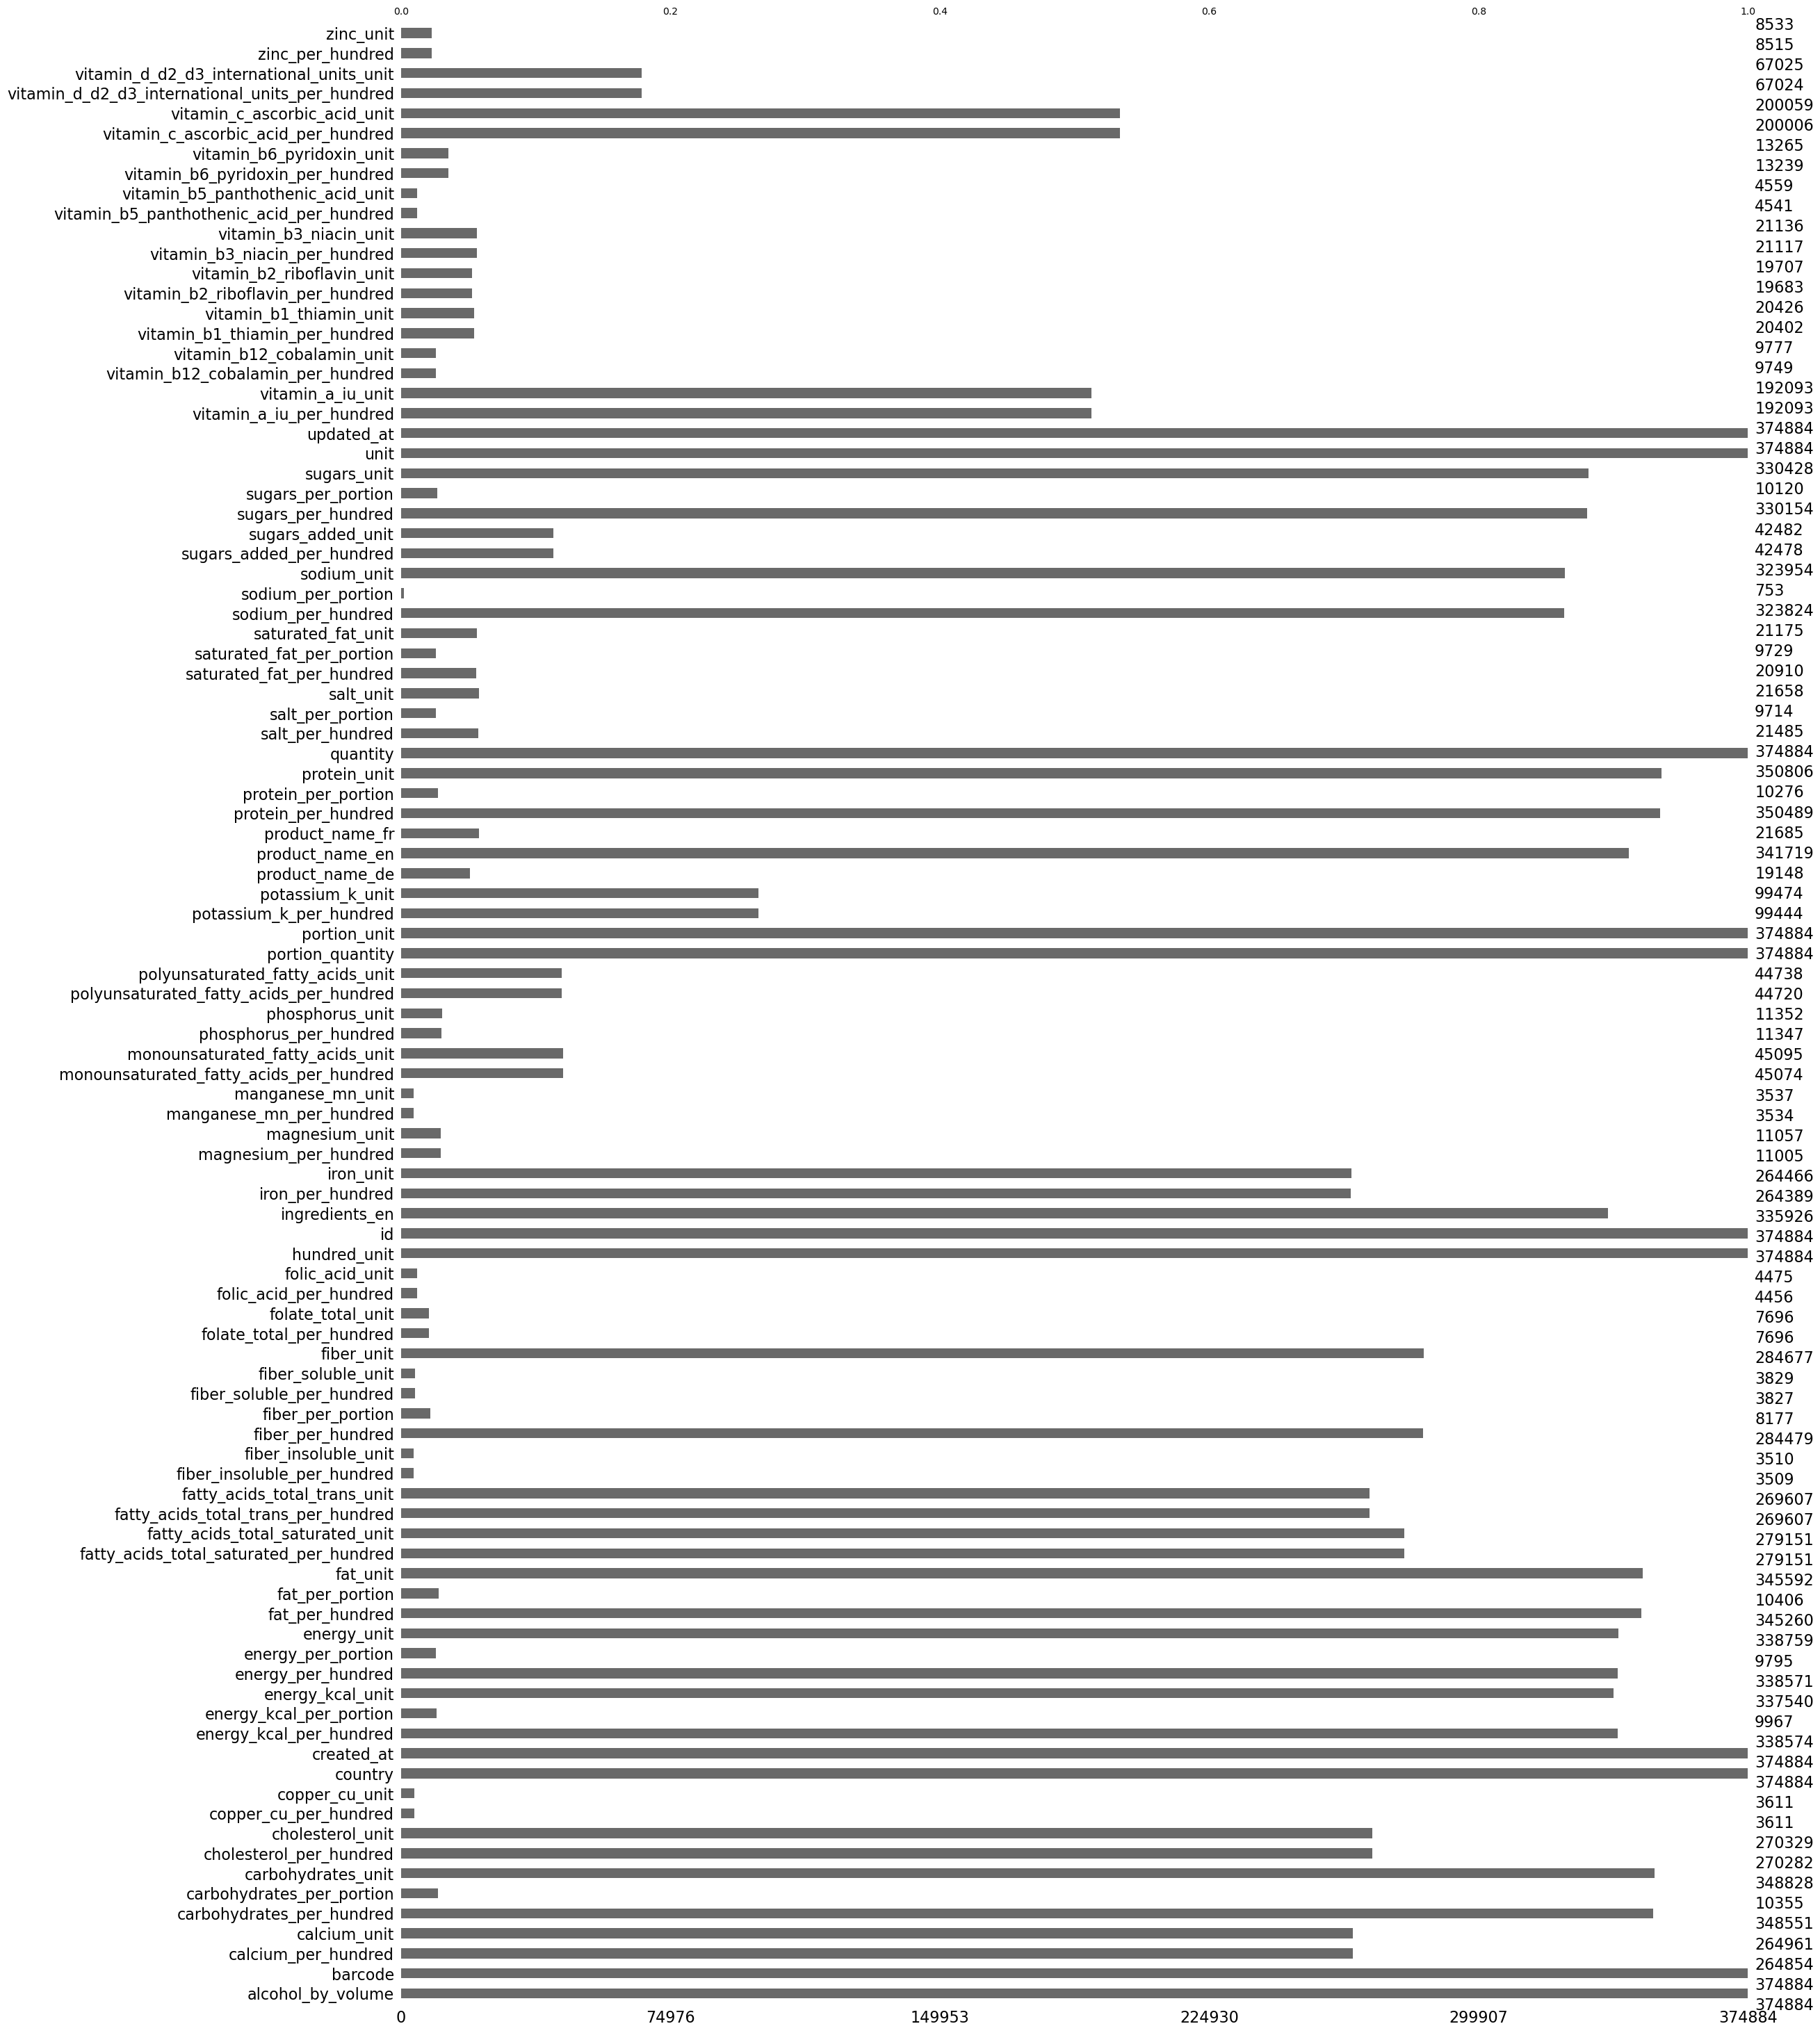

In [15]:
msno.bar(df)

According to the bar chart, the columns with no missing data are: unit,updated_at, quantity, portion_unit, portion_quantity, id, hundred_unit, created_at, country, barcode, alcohol_by_volume. Which is 11 columns in total for 99 columns. Not a lot. We could also see the columns with the most missing values sodium_per_portion being the one with the least values.

Due to the amount of columns we have in this data set, the matrix and heatmap options are almost unreadable. (`msno.matrix(df)`,`msno.heatmap(df)`)

   c. **The lists for the `_per_hundred`, `_per_portion` and `_unit` columns, and the remaining columns: 4 plots that show the percentages of missing values in each list**

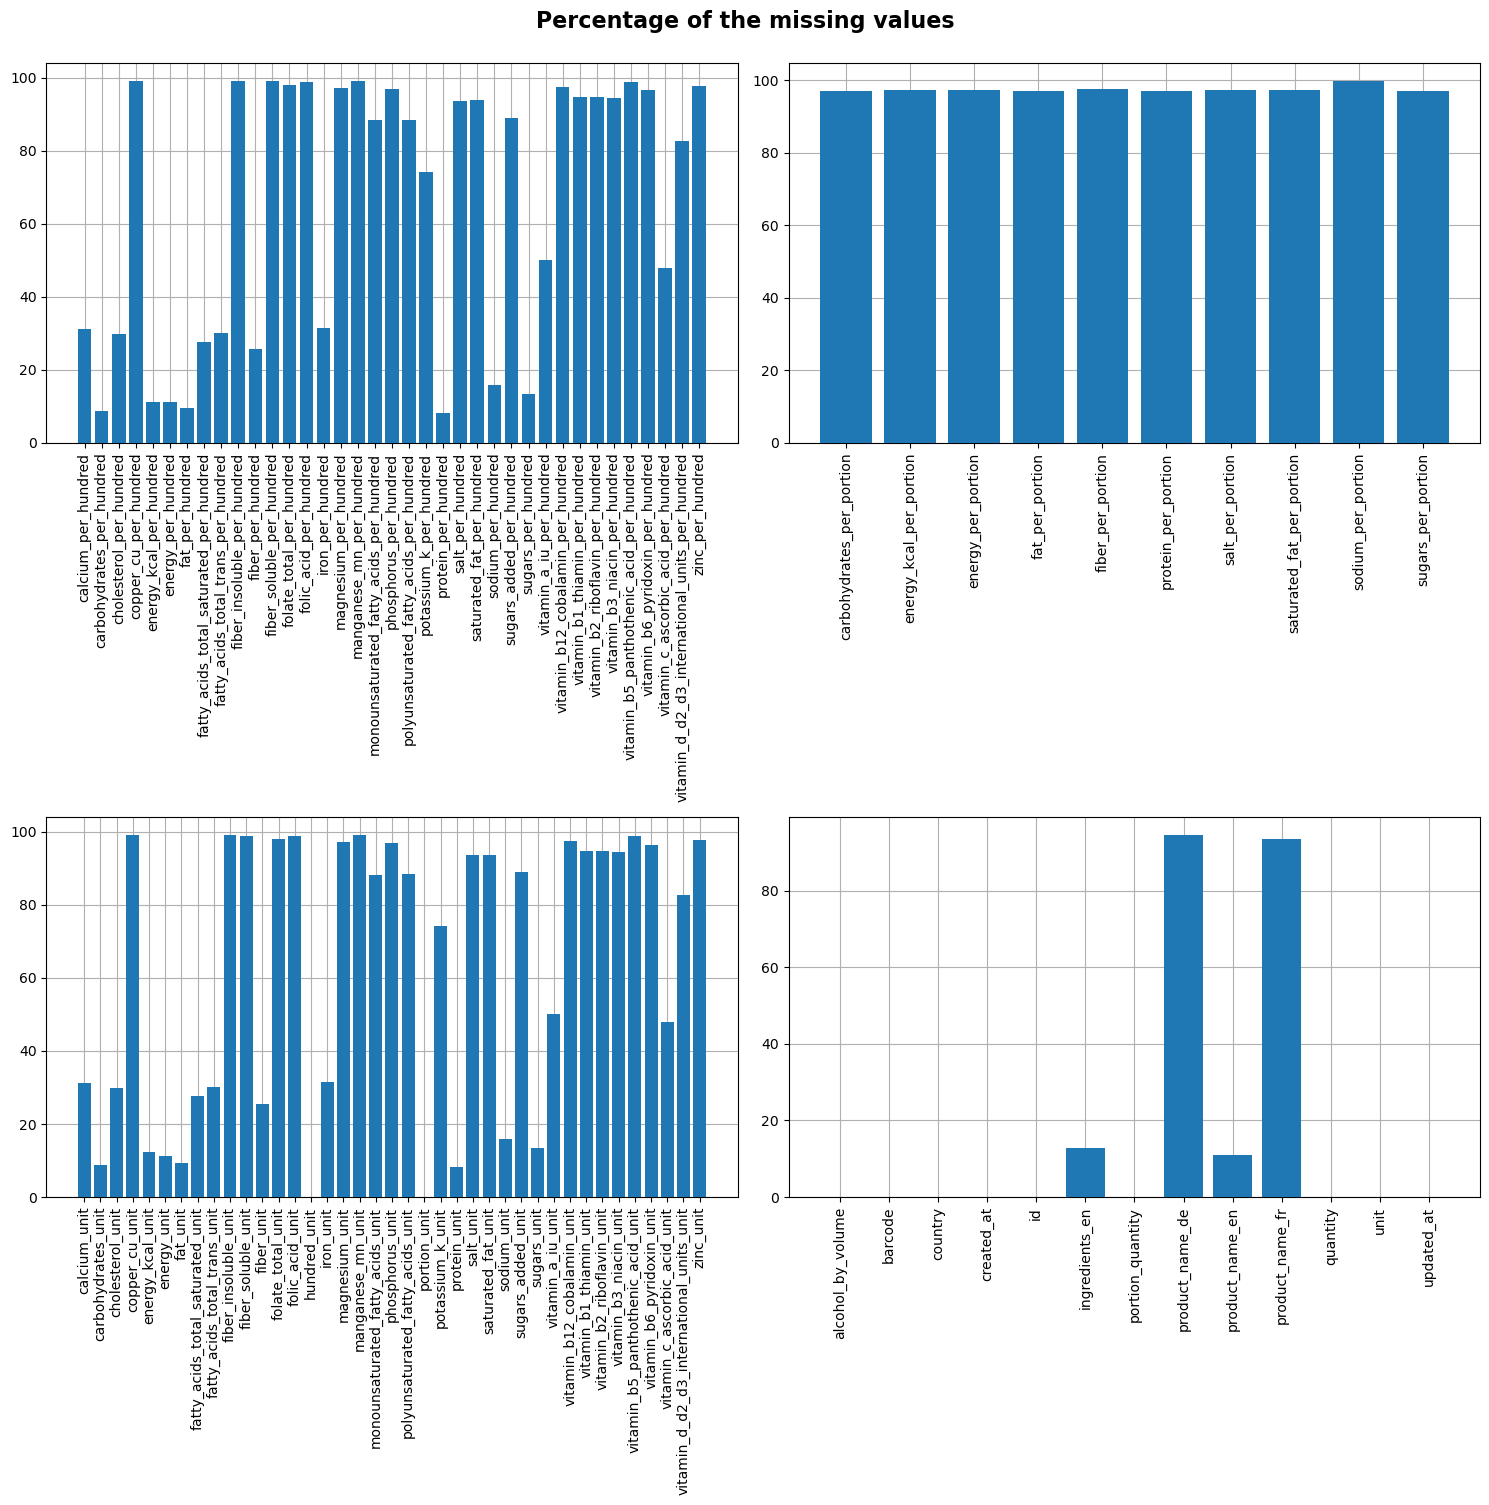

In [16]:
A_missing_value_percentage = (A.isnull().sum()/ len(A)) *100  #_per_hundred
B_missing_value_percentage = (B.isnull().sum()/ len(B)) *100 #_per_portion
C_missing_value_percentage = (C.isnull().sum()/ len(C)) *100 #_unit
other_cols_missing_value_percentage = (other_cols.isnull().sum()/ len(other_cols)) *100 #the rest of the columns

fig, ax = plt.subplots(2, 2, figsize=(15, 15))

ax[0,0].bar(A.columns,A_missing_value_percentage, zorder=3) 
ax[0,0].tick_params(axis="x", labelrotation=90)
ax[0,0].grid(zorder=0)

ax[0,1].bar(B.columns,B_missing_value_percentage, zorder=3)
ax[0,1].tick_params(axis="x", labelrotation=90)
ax[0,1].grid(zorder=0)

ax[1,0].bar(C.columns,C_missing_value_percentage, zorder=3)
ax[1,0].tick_params(axis="x", labelrotation=90)
ax[1,0].grid(zorder=0)

ax[1,1].bar(other_cols.columns,other_cols_missing_value_percentage, zorder=3)
ax[1,1].tick_params(axis="x", labelrotation=90)
ax[1,1].grid(zorder=0)

fig.suptitle("Percentage of the missing values", fontsize=16, fontweight="bold", y=1)
fig.tight_layout()

plt.show()

<AxesSubplot:>

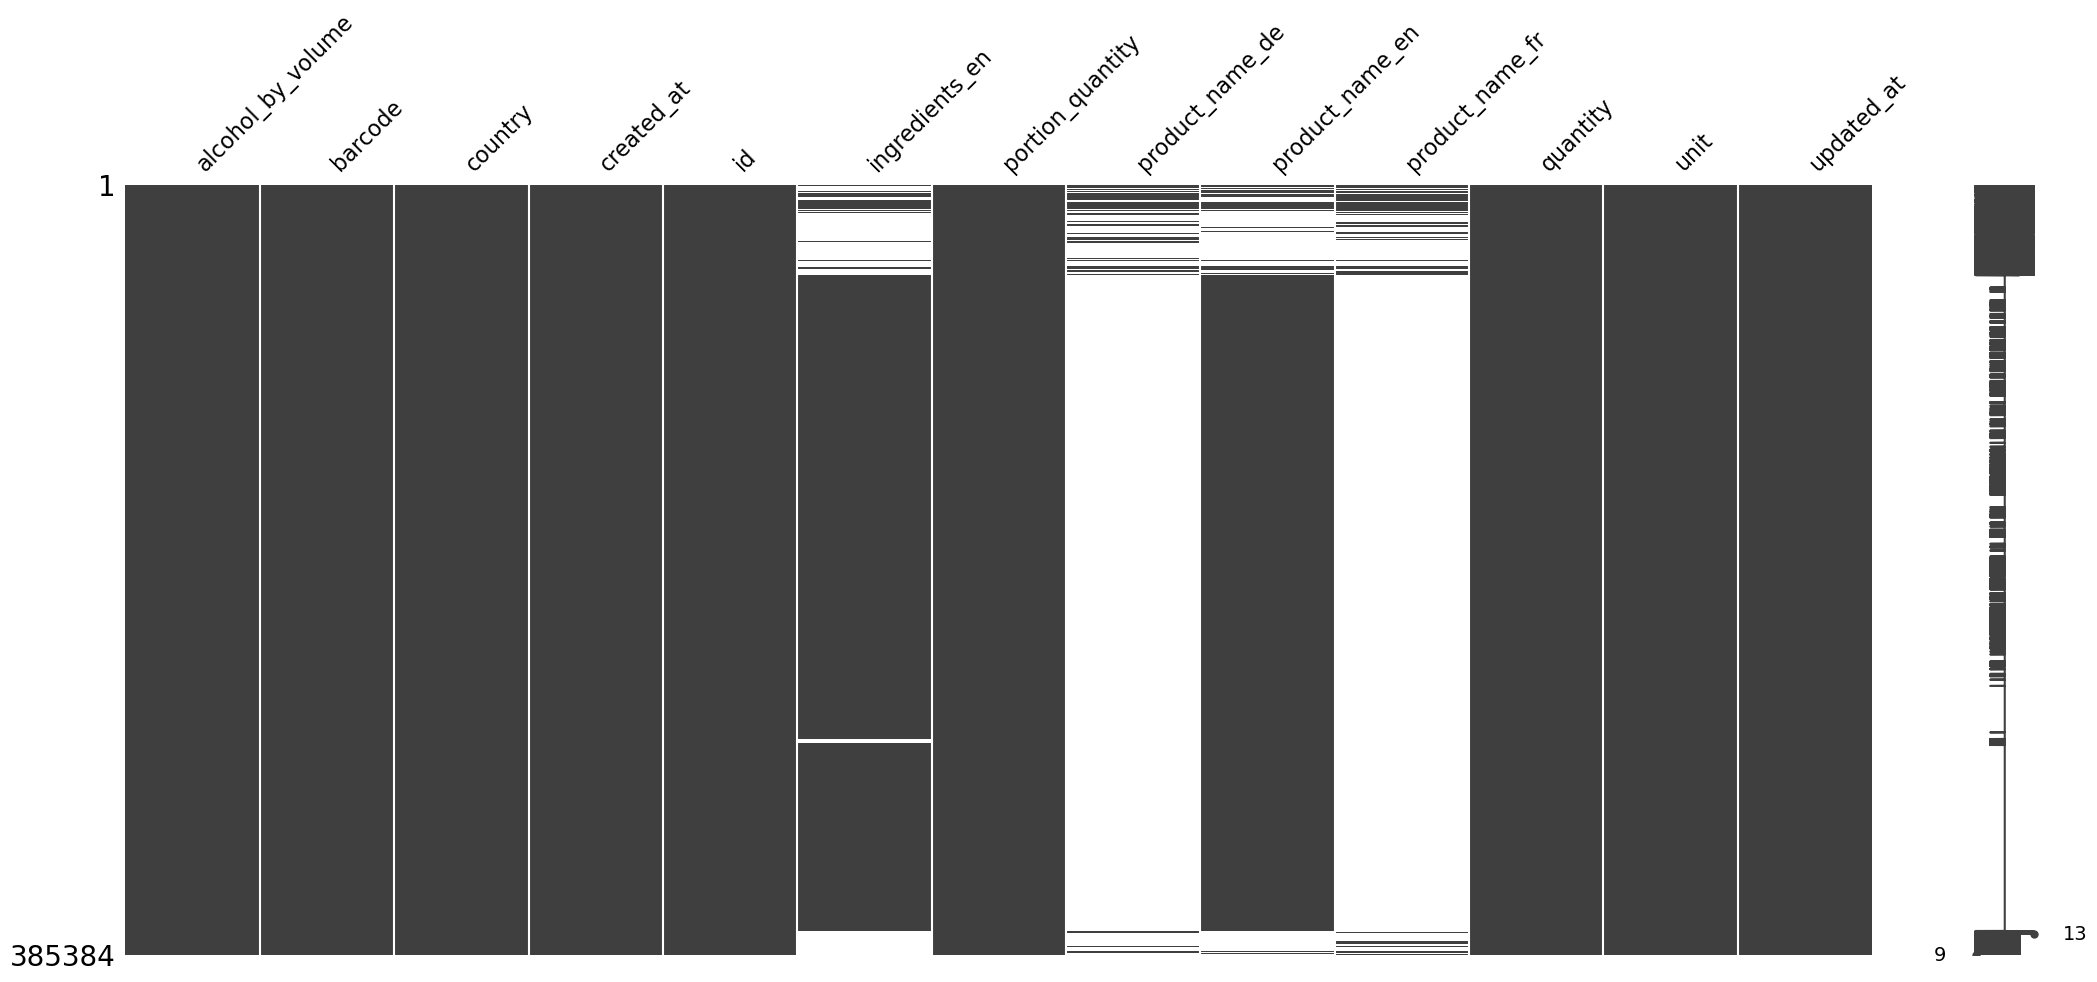

In [17]:
msno.matrix(other_cols)

<AxesSubplot:>

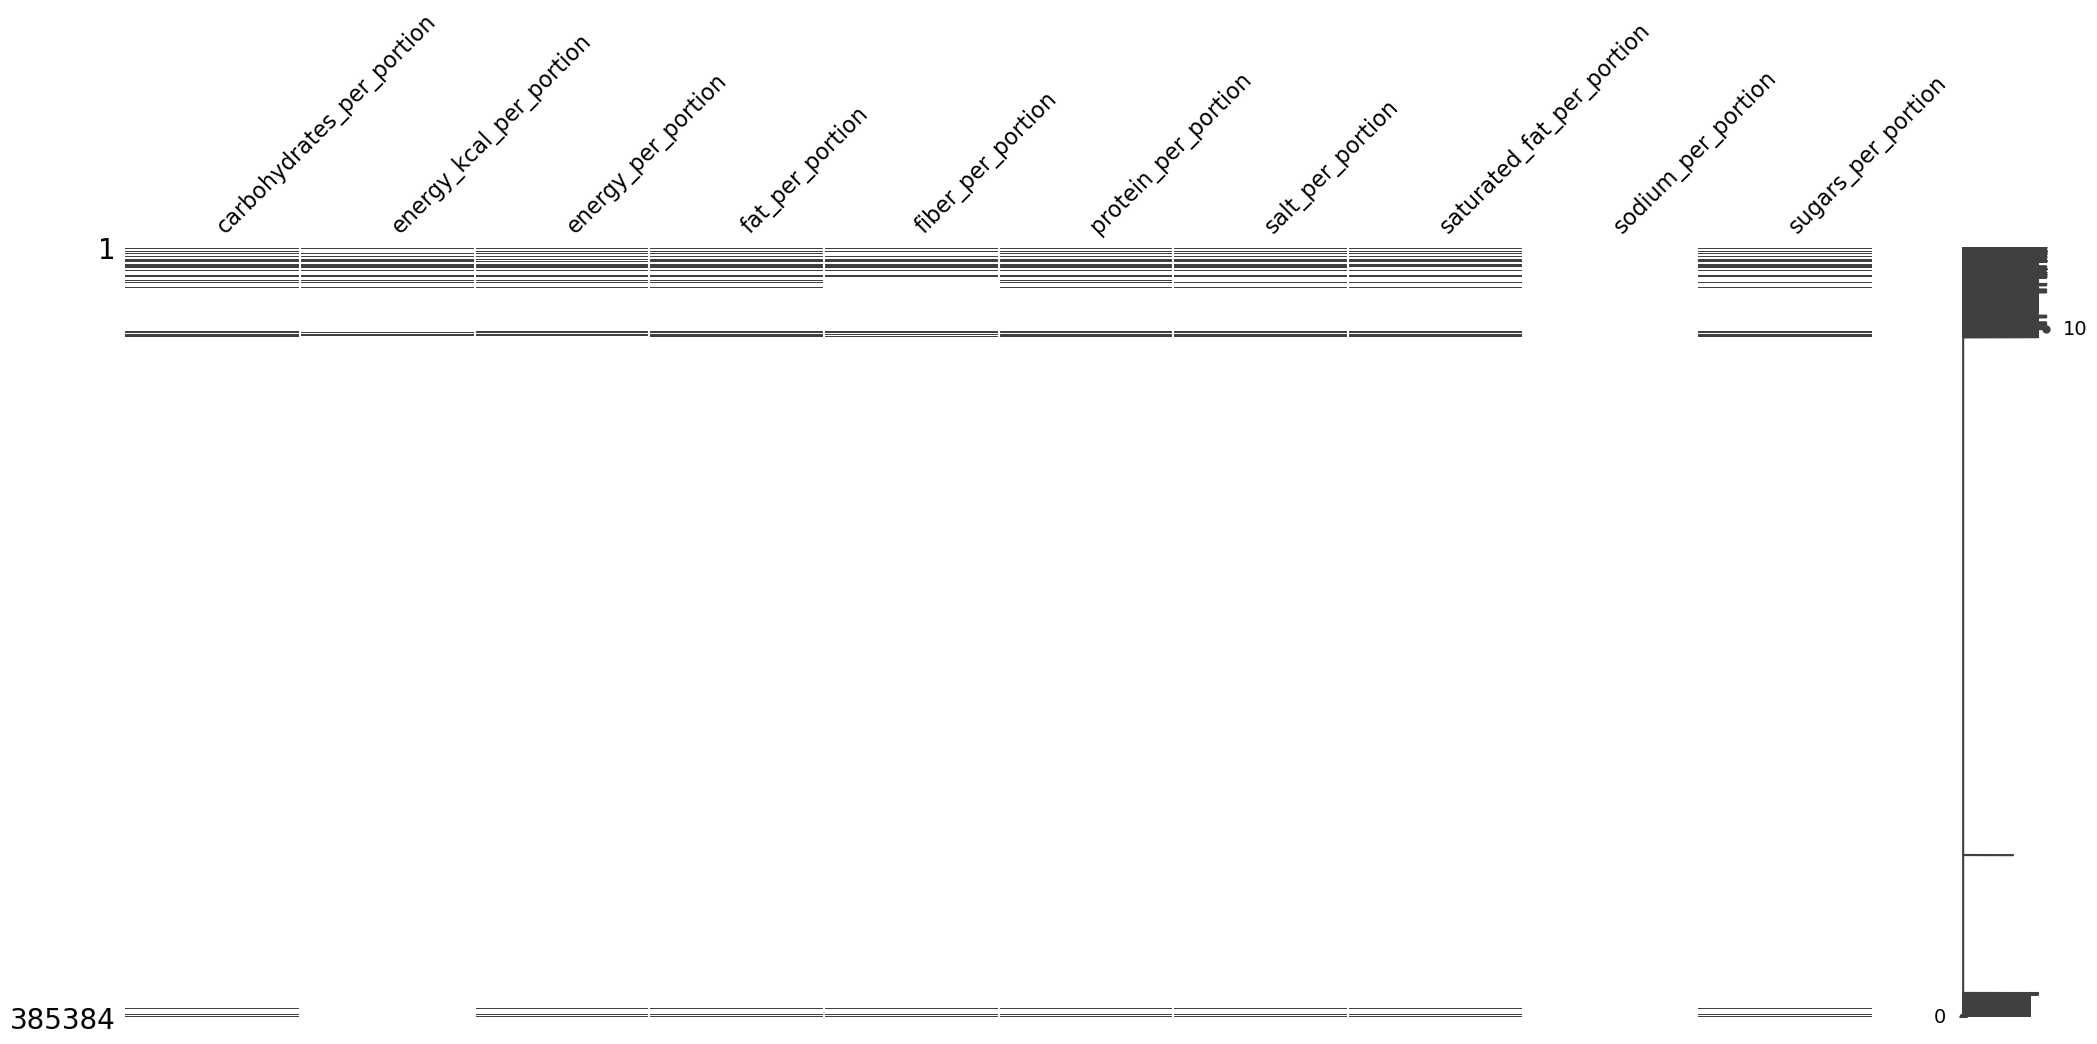

In [18]:
msno.matrix(B)

The `msno.matrix(df)` are more visible now with the reduced columns. As it can be seen in the second matrix graph and also the bar chart, the `_per_portion` list are the one with the most missing values.

3. **Addressing the missing data:**

   a. **Remove rows and columns that are completely empty:**

In [19]:
np.where(df.isnull().all(axis=1))

(array([], dtype=int64),)

In [20]:
B_missing_value_percentage

carbohydrates_per_portion    97.021153
energy_kcal_per_portion      97.413748
energy_per_portion           97.166463
fat_per_portion              97.007919
fiber_per_portion            97.683609
protein_per_portion          97.041652
salt_per_portion             97.252351
saturated_fat_per_portion    97.216023
sodium_per_portion           99.739740
sugars_per_portion           97.082131
dtype: float64

These two results show that there is no row or column that is completely empty.

   b. **List of `_unit` columns:**

In [21]:
C

,calcium_unit,carbohydrates_unit,cholesterol_unit,copper_cu_unit,energy_kcal_unit,energy_unit,fat_unit,fatty_acids_total_saturated_unit,fatty_acids_total_trans_unit,fiber_insoluble_unit,...,vitamin_a_iu_unit,vitamin_b12_cobalamin_unit,vitamin_b1_thiamin_unit,vitamin_b2_riboflavin_unit,vitamin_b3_niacin_unit,vitamin_b5_panthothenic_acid_unit,vitamin_b6_pyridoxin_unit,vitamin_c_ascorbic_acid_unit,vitamin_d_d2_d3_international_units_unit,zinc_unit
0,NaN,g,NaN,NaN,kCal,kJ,g,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,NaN,g,NaN,NaN,kCal,kJ,g,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,NaN,g,NaN,NaN,kCal,kJ,g,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,NaN,g,NaN,NaN,kCal,kJ,g,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,NaN,g,NaN,NaN,kCal,kJ,g,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
385379,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
385380,mg,g,NaN,NaN,NaN,kJ,g,NaN,NaN,NaN,...,NaN,µg,mg,mg,mg,mg,mg,mg,NaN,mg
385381,NaN,g,NaN,NaN,NaN,kJ,g,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
385382,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [22]:
C["calcium_unit"].value_counts()

mg    265086
Name: calcium_unit, dtype: int64

In [23]:
C["calcium_unit"].isna().sum()

120298

In [24]:
C["calcium_unit"].mode()[0]

'mg'

In [25]:
for column in C.columns:
    C[column].fillna(value=C[column].mode()[0], inplace=True)

In [26]:
C

,calcium_unit,carbohydrates_unit,cholesterol_unit,copper_cu_unit,energy_kcal_unit,energy_unit,fat_unit,fatty_acids_total_saturated_unit,fatty_acids_total_trans_unit,fiber_insoluble_unit,...,vitamin_a_iu_unit,vitamin_b12_cobalamin_unit,vitamin_b1_thiamin_unit,vitamin_b2_riboflavin_unit,vitamin_b3_niacin_unit,vitamin_b5_panthothenic_acid_unit,vitamin_b6_pyridoxin_unit,vitamin_c_ascorbic_acid_unit,vitamin_d_d2_d3_international_units_unit,zinc_unit
0,mg,g,mg,mg,kCal,kJ,g,g,g,g,...,IU,µg,mg,mg,mg,mg,mg,mg,IU,mg
1,mg,g,mg,mg,kCal,kJ,g,g,g,g,...,IU,µg,mg,mg,mg,mg,mg,mg,IU,mg
2,mg,g,mg,mg,kCal,kJ,g,g,g,g,...,IU,µg,mg,mg,mg,mg,mg,mg,IU,mg
3,mg,g,mg,mg,kCal,kJ,g,g,g,g,...,IU,µg,mg,mg,mg,mg,mg,mg,IU,mg
4,mg,g,mg,mg,kCal,kJ,g,g,g,g,...,IU,µg,mg,mg,mg,mg,mg,mg,IU,mg
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
385379,mg,g,mg,mg,kCal,kJ,g,g,g,g,...,IU,µg,mg,mg,mg,mg,mg,mg,IU,mg
385380,mg,g,mg,mg,kCal,kJ,g,g,g,g,...,IU,µg,mg,mg,mg,mg,mg,mg,IU,mg
385381,mg,g,mg,mg,kCal,kJ,g,g,g,g,...,IU,µg,mg,mg,mg,mg,mg,mg,IU,mg
385382,mg,g,mg,mg,kCal,kJ,g,g,g,g,...,IU,µg,mg,mg,mg,mg,mg,mg,IU,mg


In [27]:
C.isnull().sum()

calcium_unit                                0
carbohydrates_unit                          0
cholesterol_unit                            0
copper_cu_unit                              0
energy_kcal_unit                            0
energy_unit                                 0
fat_unit                                    0
fatty_acids_total_saturated_unit            0
fatty_acids_total_trans_unit                0
fiber_insoluble_unit                        0
fiber_soluble_unit                          0
fiber_unit                                  0
folate_total_unit                           0
folic_acid_unit                             0
hundred_unit                                0
iron_unit                                   0
magnesium_unit                              0
manganese_mn_unit                           0
monounsaturated_fatty_acids_unit            0
phosphorus_unit                             0
polyunsaturated_fatty_acids_unit            0
portion_unit                      

   c. **Fill up the missing values of a column using other columns that hold similar information:**

In [28]:
other_cols

,alcohol_by_volume,barcode,country,created_at,id,ingredients_en,portion_quantity,product_name_de,product_name_en,product_name_fr,quantity,unit,updated_at
0,0.0,8001772000030,CH,2016-06-01T11:42:22.908Z,1000,Superior quality durum wheat Pasta\r\n\r\nIngr...,50.0,Bio Spaghetti,Bio Spaghetti,Spaghetti Bio,500.0,g,2019-10-30T13:46:32.651Z
1,0.0,7610809001066,CH,2016-06-01T11:42:25.111Z,1001,"Bio Milk (Switzerland), kitchen salt",75.0,Naturaplan Mozzarella,Naturaplan Mozzarella,Naturaplan Mozzarella,150.0,g,2019-10-30T13:47:12.174Z
2,0.0,8002530159021,CH,2016-06-01T11:42:25.900Z,1002,100% coffee Arabica,0.0,Caffè Mauro - Bio Kaffe,Caffè Mauro - Roasted organic coffee blend,Caffè Mauro - café bio,1000.0,g,2019-10-30T13:48:12.635Z
3,0.0,3033715065788,CH,2016-06-01T11:42:26.184Z,1003,"Powdered chocolate 99% (sugar, cocoa), emulsif...",17.0,Le chocolat Cailler - schokoladenpulver,Le chocolat Cailler - chocolate powder,Le chocolat Cailler - chocolat en poudre,500.0,g,2019-10-30T13:49:49.816Z
4,0.0,7610848492740,CH,2016-06-01T11:42:26.350Z,1004,"cocoa paste * (Honduras), raw cane sugar * (Pa...",20.0,Naturaplan ExtraDunkle Schokolade 70%,Naturaplan Extra Dark Chocolate 70%,Naturaplan Chocolat extra noir 70%,100.0,g,2019-10-30T13:50:42.826Z
...,...,...,...,...,...,...,...,...,...,...,...,...,...
385379,0.0,7640145040283,CH,2021-10-04T14:08:42.215Z,376939,NaN,0.0,NaN,Nutriathletic - Whey (Swiss chocolate flavour),NaN,800.0,g,2021-10-04T14:12:00.863Z
385380,0.0,7640147023628,CH,2021-10-04T14:12:06.476Z,376940,NaN,20.0,Bourquin nutrition - Sportgetränk (Zitronenges...,NaN,Bourquin nutrition - Boisson d'effort (Goût ci...,480.0,g,2021-10-04T14:21:57.692Z
385381,0.0,3046920021593,CH,2021-10-04T14:22:10.685Z,376941,"cocoa mass, fat reduced cocoa, cocoa butter, d...",0.0,NaN,NaN,Lindt - Noir puissant 85% cacao,100.0,g,2021-10-04T14:27:23.319Z
385382,0.0,4044889004335,CH,2021-10-04T14:27:36.157Z,376942,NaN,0.0,NaN,NaN,NaN,0.0,?,2021-10-04T14:27:43.384Z


In [29]:
other_cols["product_name_en"].isna().sum()

42540

In [30]:
other_cols["product_name_fr"].isna().sum()

359824

In [31]:
other_cols["product_name_de"].isna().sum()

363986

In [32]:
other_cols["product_name_en"]=other_cols["product_name_en"].fillna(other_cols["product_name_fr"])

In [33]:
other_cols["product_name_en"].isna().sum()

27296

In [34]:
other_cols["product_name_en"]=other_cols["product_name_en"].fillna(other_cols["product_name_de"])

In [35]:
other_cols["product_name_en"].isna().sum()

24241

In [36]:
other_cols["product_name_de"]=other_cols["product_name_de"].fillna(other_cols["product_name_en"])
other_cols["product_name_fr"]=other_cols["product_name_fr"].fillna(other_cols["product_name_en"])

In [37]:
other_cols

,alcohol_by_volume,barcode,country,created_at,id,ingredients_en,portion_quantity,product_name_de,product_name_en,product_name_fr,quantity,unit,updated_at
0,0.0,8001772000030,CH,2016-06-01T11:42:22.908Z,1000,Superior quality durum wheat Pasta\r\n\r\nIngr...,50.0,Bio Spaghetti,Bio Spaghetti,Spaghetti Bio,500.0,g,2019-10-30T13:46:32.651Z
1,0.0,7610809001066,CH,2016-06-01T11:42:25.111Z,1001,"Bio Milk (Switzerland), kitchen salt",75.0,Naturaplan Mozzarella,Naturaplan Mozzarella,Naturaplan Mozzarella,150.0,g,2019-10-30T13:47:12.174Z
2,0.0,8002530159021,CH,2016-06-01T11:42:25.900Z,1002,100% coffee Arabica,0.0,Caffè Mauro - Bio Kaffe,Caffè Mauro - Roasted organic coffee blend,Caffè Mauro - café bio,1000.0,g,2019-10-30T13:48:12.635Z
3,0.0,3033715065788,CH,2016-06-01T11:42:26.184Z,1003,"Powdered chocolate 99% (sugar, cocoa), emulsif...",17.0,Le chocolat Cailler - schokoladenpulver,Le chocolat Cailler - chocolate powder,Le chocolat Cailler - chocolat en poudre,500.0,g,2019-10-30T13:49:49.816Z
4,0.0,7610848492740,CH,2016-06-01T11:42:26.350Z,1004,"cocoa paste * (Honduras), raw cane sugar * (Pa...",20.0,Naturaplan ExtraDunkle Schokolade 70%,Naturaplan Extra Dark Chocolate 70%,Naturaplan Chocolat extra noir 70%,100.0,g,2019-10-30T13:50:42.826Z
...,...,...,...,...,...,...,...,...,...,...,...,...,...
385379,0.0,7640145040283,CH,2021-10-04T14:08:42.215Z,376939,NaN,0.0,Nutriathletic - Whey (Swiss chocolate flavour),Nutriathletic - Whey (Swiss chocolate flavour),Nutriathletic - Whey (Swiss chocolate flavour),800.0,g,2021-10-04T14:12:00.863Z
385380,0.0,7640147023628,CH,2021-10-04T14:12:06.476Z,376940,NaN,20.0,Bourquin nutrition - Sportgetränk (Zitronenges...,Bourquin nutrition - Boisson d'effort (Goût ci...,Bourquin nutrition - Boisson d'effort (Goût ci...,480.0,g,2021-10-04T14:21:57.692Z
385381,0.0,3046920021593,CH,2021-10-04T14:22:10.685Z,376941,"cocoa mass, fat reduced cocoa, cocoa butter, d...",0.0,Lindt - Noir puissant 85% cacao,Lindt - Noir puissant 85% cacao,Lindt - Noir puissant 85% cacao,100.0,g,2021-10-04T14:27:23.319Z
385382,0.0,4044889004335,CH,2021-10-04T14:27:36.157Z,376942,NaN,0.0,NaN,NaN,NaN,0.0,?,2021-10-04T14:27:43.384Z


Using `product_name_de` and `product_name_fr` to fill `product_name_en` with the missing names in either languages. I managed to fill 14299 rows. The missing values for the names are now down to 18866. I did the same to `product_name_de` and `product_name_fr`.

   d. **Fill up missing values based on common knowledge:**

One possible explanation for its missing values could be that those products are iron-free (like ice cream). Based on this assumption let's address the missing values for `iron_per_hundred`. Since the values in the columns are float64, I put value as 0 instead or the "iron-free" object to keep it more cohesive.

In [38]:
A["iron_per_hundred"].isna().sum()

120995

In [39]:
A["iron_per_hundred"].fillna(value=0, inplace=True) 

In [40]:
A["iron_per_hundred"].isna().sum()

0

   e. **Fill up missing values in text-based columns:**

The column `ingredients_en` has about 10% of missing values. Let’s replace them with the term `ingredient_missing`.

In [41]:
other_cols["ingredients_en"].isna().sum()

49083

In [42]:
other_cols["ingredients_en"].fillna(value="ingredient_missing", inplace=True)

In [43]:
other_cols["ingredients_en"].isna().sum()

0

   f. **Drop the columns that have more than 95% of missing values:**

In [44]:
A_missing_value_percentage = (A.isnull().sum()/ len(A)) *100  #_per_hundred
B_missing_value_percentage = (B.isnull().sum()/ len(B)) *100 #_per_portion
C_missing_value_percentage = (C.isnull().sum()/ len(C)) *100 #_unit
other_cols_missing_value_percentage = (other_cols.isnull().sum()/ len(other_cols)) *100 #the rest of the columns

In [45]:
A_missing_value_percentage

calcium_per_hundred                                31.242864
carbohydrates_per_hundred                           8.779036
cholesterol_per_hundred                            29.866834
copper_cu_per_hundred                              99.063012
energy_kcal_per_hundred                            11.303012
energy_per_hundred                                 11.303791
fat_per_hundred                                     9.535684
fatty_acids_total_saturated_per_hundred            27.565493
fatty_acids_total_trans_per_hundred                30.041984
fiber_insoluble_per_hundred                        99.089480
fiber_per_hundred                                  25.599143
fiber_soluble_per_hundred                          99.006964
folate_total_per_hundred                           98.003031
folic_acid_per_hundred                             98.811315
iron_per_hundred                                    0.000000
magnesium_per_hundred                              97.111971
manganese_mn_per_hundred

In [46]:
B_missing_value_percentage

carbohydrates_per_portion    97.021153
energy_kcal_per_portion      97.413748
energy_per_portion           97.166463
fat_per_portion              97.007919
fiber_per_portion            97.683609
protein_per_portion          97.041652
salt_per_portion             97.252351
saturated_fat_per_portion    97.216023
sodium_per_portion           99.739740
sugars_per_portion           97.082131
dtype: float64

In [47]:
C_missing_value_percentage

calcium_unit                                0.0
carbohydrates_unit                          0.0
cholesterol_unit                            0.0
copper_cu_unit                              0.0
energy_kcal_unit                            0.0
energy_unit                                 0.0
fat_unit                                    0.0
fatty_acids_total_saturated_unit            0.0
fatty_acids_total_trans_unit                0.0
fiber_insoluble_unit                        0.0
fiber_soluble_unit                          0.0
fiber_unit                                  0.0
folate_total_unit                           0.0
folic_acid_unit                             0.0
hundred_unit                                0.0
iron_unit                                   0.0
magnesium_unit                              0.0
manganese_mn_unit                           0.0
monounsaturated_fatty_acids_unit            0.0
phosphorus_unit                             0.0
polyunsaturated_fatty_acids_unit        

In [48]:
other_cols_missing_value_percentage

alcohol_by_volume    0.00000
barcode              0.00000
country              0.00000
created_at           0.00000
id                   0.00000
ingredients_en       0.00000
portion_quantity     0.00000
product_name_de      6.29009
product_name_en      6.29009
product_name_fr      6.29009
quantity             0.00000
unit                 0.00000
updated_at           0.00000
dtype: float64

In [49]:
A_drop95 = A_missing_value_percentage[A_missing_value_percentage > 95].index
A = A.drop(columns = A_drop95)

B_drop95 = B_missing_value_percentage[B_missing_value_percentage > 95].index
B = B.drop(columns = B_drop95)

C_drop95 = C_missing_value_percentage[C_missing_value_percentage > 95].index
C = C.drop(columns = C_drop95)

other_cols_drop95 = other_cols_missing_value_percentage[other_cols_missing_value_percentage > 95].index
other_cols = other_cols.drop(columns = other_cols_drop95)

In [50]:
A_missing_value_percentage = (A.isnull().sum()/ len(A)) *100  #_per_hundred
B_missing_value_percentage = (B.isnull().sum()/ len(B)) *100 #_per_portion
C_missing_value_percentage = (C.isnull().sum()/ len(C)) *100 #_unit
other_cols_missing_value_percentage = (other_cols.isnull().sum()/ len(other_cols)) *100 #the rest of the columns

In [51]:
A_missing_value_percentage

calcium_per_hundred                                31.242864
carbohydrates_per_hundred                           8.779036
cholesterol_per_hundred                            29.866834
energy_kcal_per_hundred                            11.303012
energy_per_hundred                                 11.303791
fat_per_hundred                                     9.535684
fatty_acids_total_saturated_per_hundred            27.565493
fatty_acids_total_trans_per_hundred                30.041984
fiber_per_hundred                                  25.599143
iron_per_hundred                                    0.000000
monounsaturated_fatty_acids_per_hundred            88.304133
polyunsaturated_fatty_acids_per_hundred            88.395989
potassium_k_per_hundred                            74.163691
protein_per_hundred                                 8.243726
salt_per_hundred                                   93.679032
saturated_fat_per_hundred                          93.795798
sodium_per_hundred      

In [52]:
B_missing_value_percentage

Series([], dtype: float64)

In [53]:
C_missing_value_percentage

calcium_unit                                0.0
carbohydrates_unit                          0.0
cholesterol_unit                            0.0
copper_cu_unit                              0.0
energy_kcal_unit                            0.0
energy_unit                                 0.0
fat_unit                                    0.0
fatty_acids_total_saturated_unit            0.0
fatty_acids_total_trans_unit                0.0
fiber_insoluble_unit                        0.0
fiber_soluble_unit                          0.0
fiber_unit                                  0.0
folate_total_unit                           0.0
folic_acid_unit                             0.0
hundred_unit                                0.0
iron_unit                                   0.0
magnesium_unit                              0.0
manganese_mn_unit                           0.0
monounsaturated_fatty_acids_unit            0.0
phosphorus_unit                             0.0
polyunsaturated_fatty_acids_unit        

In [54]:
other_cols_missing_value_percentage

alcohol_by_volume    0.00000
barcode              0.00000
country              0.00000
created_at           0.00000
id                   0.00000
ingredients_en       0.00000
portion_quantity     0.00000
product_name_de      6.29009
product_name_en      6.29009
product_name_fr      6.29009
quantity             0.00000
unit                 0.00000
updated_at           0.00000
dtype: float64

I had to put the percentages before and after the drop function to make sure I deleted all the ones that have more than 95% of missing values.

In [55]:
df_new = pd.concat([A, B, C, other_cols], axis=1)
df_new.shape

(385384, 77)

The shape of the remaining data is 385384 rows and 77 columns.

# Task C: Preliminary Exploratory Data Analysis (EDA)

1. **The number of unique values in categorical variables:**

In [56]:
df_new["country"].unique()

array(['CH', 'FR', 'IT', 'DE', 'AT', 'UK', 'US'], dtype=object)

In [57]:
Country_count=pd.DataFrame(df_new["country"].value_counts())
Country_count

,country
US,328289
CH,43617
DE,10639
IT,2719
FR,118
AT,1
UK,1


In [58]:
df_new["unit"].unique()

array(['g', 'ml', 'cl', 'l', 'dl', 'kg', 'Floz', 'Lb', 'Oz', '?'],
      dtype=object)

In [59]:
unit_count=pd.DataFrame(df_new["unit"].value_counts())
unit_count

,unit
g,330865
ml,49316
?,2772
cl,1037
l,870
kg,483
dl,29
Floz,5
Oz,4
Lb,3


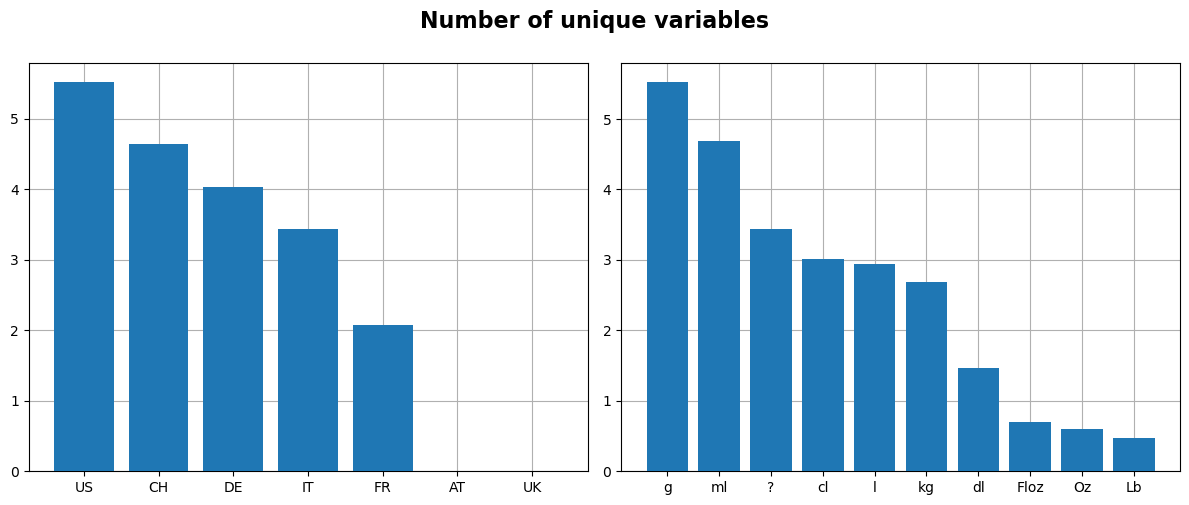

In [60]:
fig, ax = plt.subplots(1, 2, figsize=(12, 5))

ax[0].bar(Country_count.index, np.log10(Country_count.country), zorder=3) 
#ax[0].tick_params(axis="x", labelrotation=90)
ax[0].grid(zorder=0)

ax[1].bar(unit_count.index, np.log10(unit_count.unit), zorder=3)
#ax[1].tick_params(axis="x", labelrotation=90)
ax[1].grid(zorder=0)

fig.suptitle("Number of unique variables", fontsize=16, fontweight="bold", y=1)
fig.tight_layout()

plt.show()

I'm not sure I understood this question correctly. I didn't know if I should count the number of unique values in all the categorical variables of the data set or just `country`and `unit`. Given the big amout of categorical values still left in this dataframe, I only did it for `country`and `unit`. For the visualization, I chose the bar chart but put the logarithm on the y axis given the amout of the `US`and `g` values. The exact number of the count is stored and displayed on the dataframes `Country_count`and `unit_count`.

In [61]:
categorical_values = df_new.loc[:, df_new.dtypes == "object"]

In [62]:
#for column in categorical_values.columns:
    #print (categorical_values[column].value_counts())

Just in case, I put this function that prints the value counts in each column of the categorical values. However, I put it in comment since the answer takes so much space.

barcode is included in the `categorical_values` because it's still considered as `object` in the data set, also `id` is left out because it's an `int64`. This is not a problem since we are not interested in them for this part. 

2. **For the numerical variables provide descriptive statistics and informative plots:**

In [63]:
numerical_values = df_new.loc[:, df_new.dtypes == "float64"]

In [64]:
numerical_values.describe()

,calcium_per_hundred,carbohydrates_per_hundred,cholesterol_per_hundred,energy_kcal_per_hundred,energy_per_hundred,fat_per_hundred,fatty_acids_total_saturated_per_hundred,fatty_acids_total_trans_per_hundred,fiber_per_hundred,iron_per_hundred,...,sugars_per_hundred,vitamin_a_iu_per_hundred,vitamin_b1_thiamin_per_hundred,vitamin_b2_riboflavin_per_hundred,vitamin_b3_niacin_per_hundred,vitamin_c_ascorbic_acid_per_hundred,vitamin_d_d2_d3_international_units_per_hundred,alcohol_by_volume,portion_quantity,quantity
count,264979.000000,351551.000000,270282.000000,341824.000000,341821.000000,348635.000000,279151.000000,269607.000000,286729.000000,385384.000000,...,333279.000000,192093.000000,20527.000000,19808.000000,21242.000000,200256.000000,67024.000000,385384.000000,385384.000000,385384.000000
mean,116.993353,33.898029,58.981358,272.087276,1137.840335,12.720908,4.943331,0.034861,2.923297,5.228436,...,16.958125,494.236708,0.969930,1.735762,10.494692,16.004049,14.186515,0.031529,4.182835,97.549000
std,2557.356337,40.719059,1934.718972,257.834527,1077.750446,19.492152,8.500435,1.285369,5.878018,1309.558164,...,31.070461,2445.251154,13.461135,142.161277,73.349425,583.402603,73.262518,0.796383,33.045307,400.337478
min,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,0.000000,6.670000,0.000000,89.000000,372.380000,0.000000,0.000000,0.000000,0.000000,0.000000,...,1.670000,0.000000,0.000000,0.200000,3.020000,0.000000,0.000000,0.000000,0.000000,28.000000
50%,36.000000,23.440000,0.000000,267.000000,1117.130000,5.470000,2.000000,0.000000,1.600000,0.000000,...,6.450000,0.000000,0.000000,0.340000,5.000000,0.000000,0.000000,0.000000,0.000000,43.000000
75%,102.000000,60.000000,25.000000,400.000000,1673.600000,20.000000,7.140000,0.000000,3.600000,1.590000,...,25.000000,352.000000,1.000000,0.610000,8.330000,4.000000,0.000000,0.000000,0.000000,120.000000
max,684000.000000,6400.000000,250000.000000,39600.000000,165686.400000,3200.000000,1000.000000,615.380000,1730.000000,769230.770000,...,5800.000000,333333.000000,1111.000000,20000.000000,6785.710000,210000.000000,5000.000000,57.900000,3000.000000,230000.000000


In [65]:
stats_num = numerical_values.describe().copy()

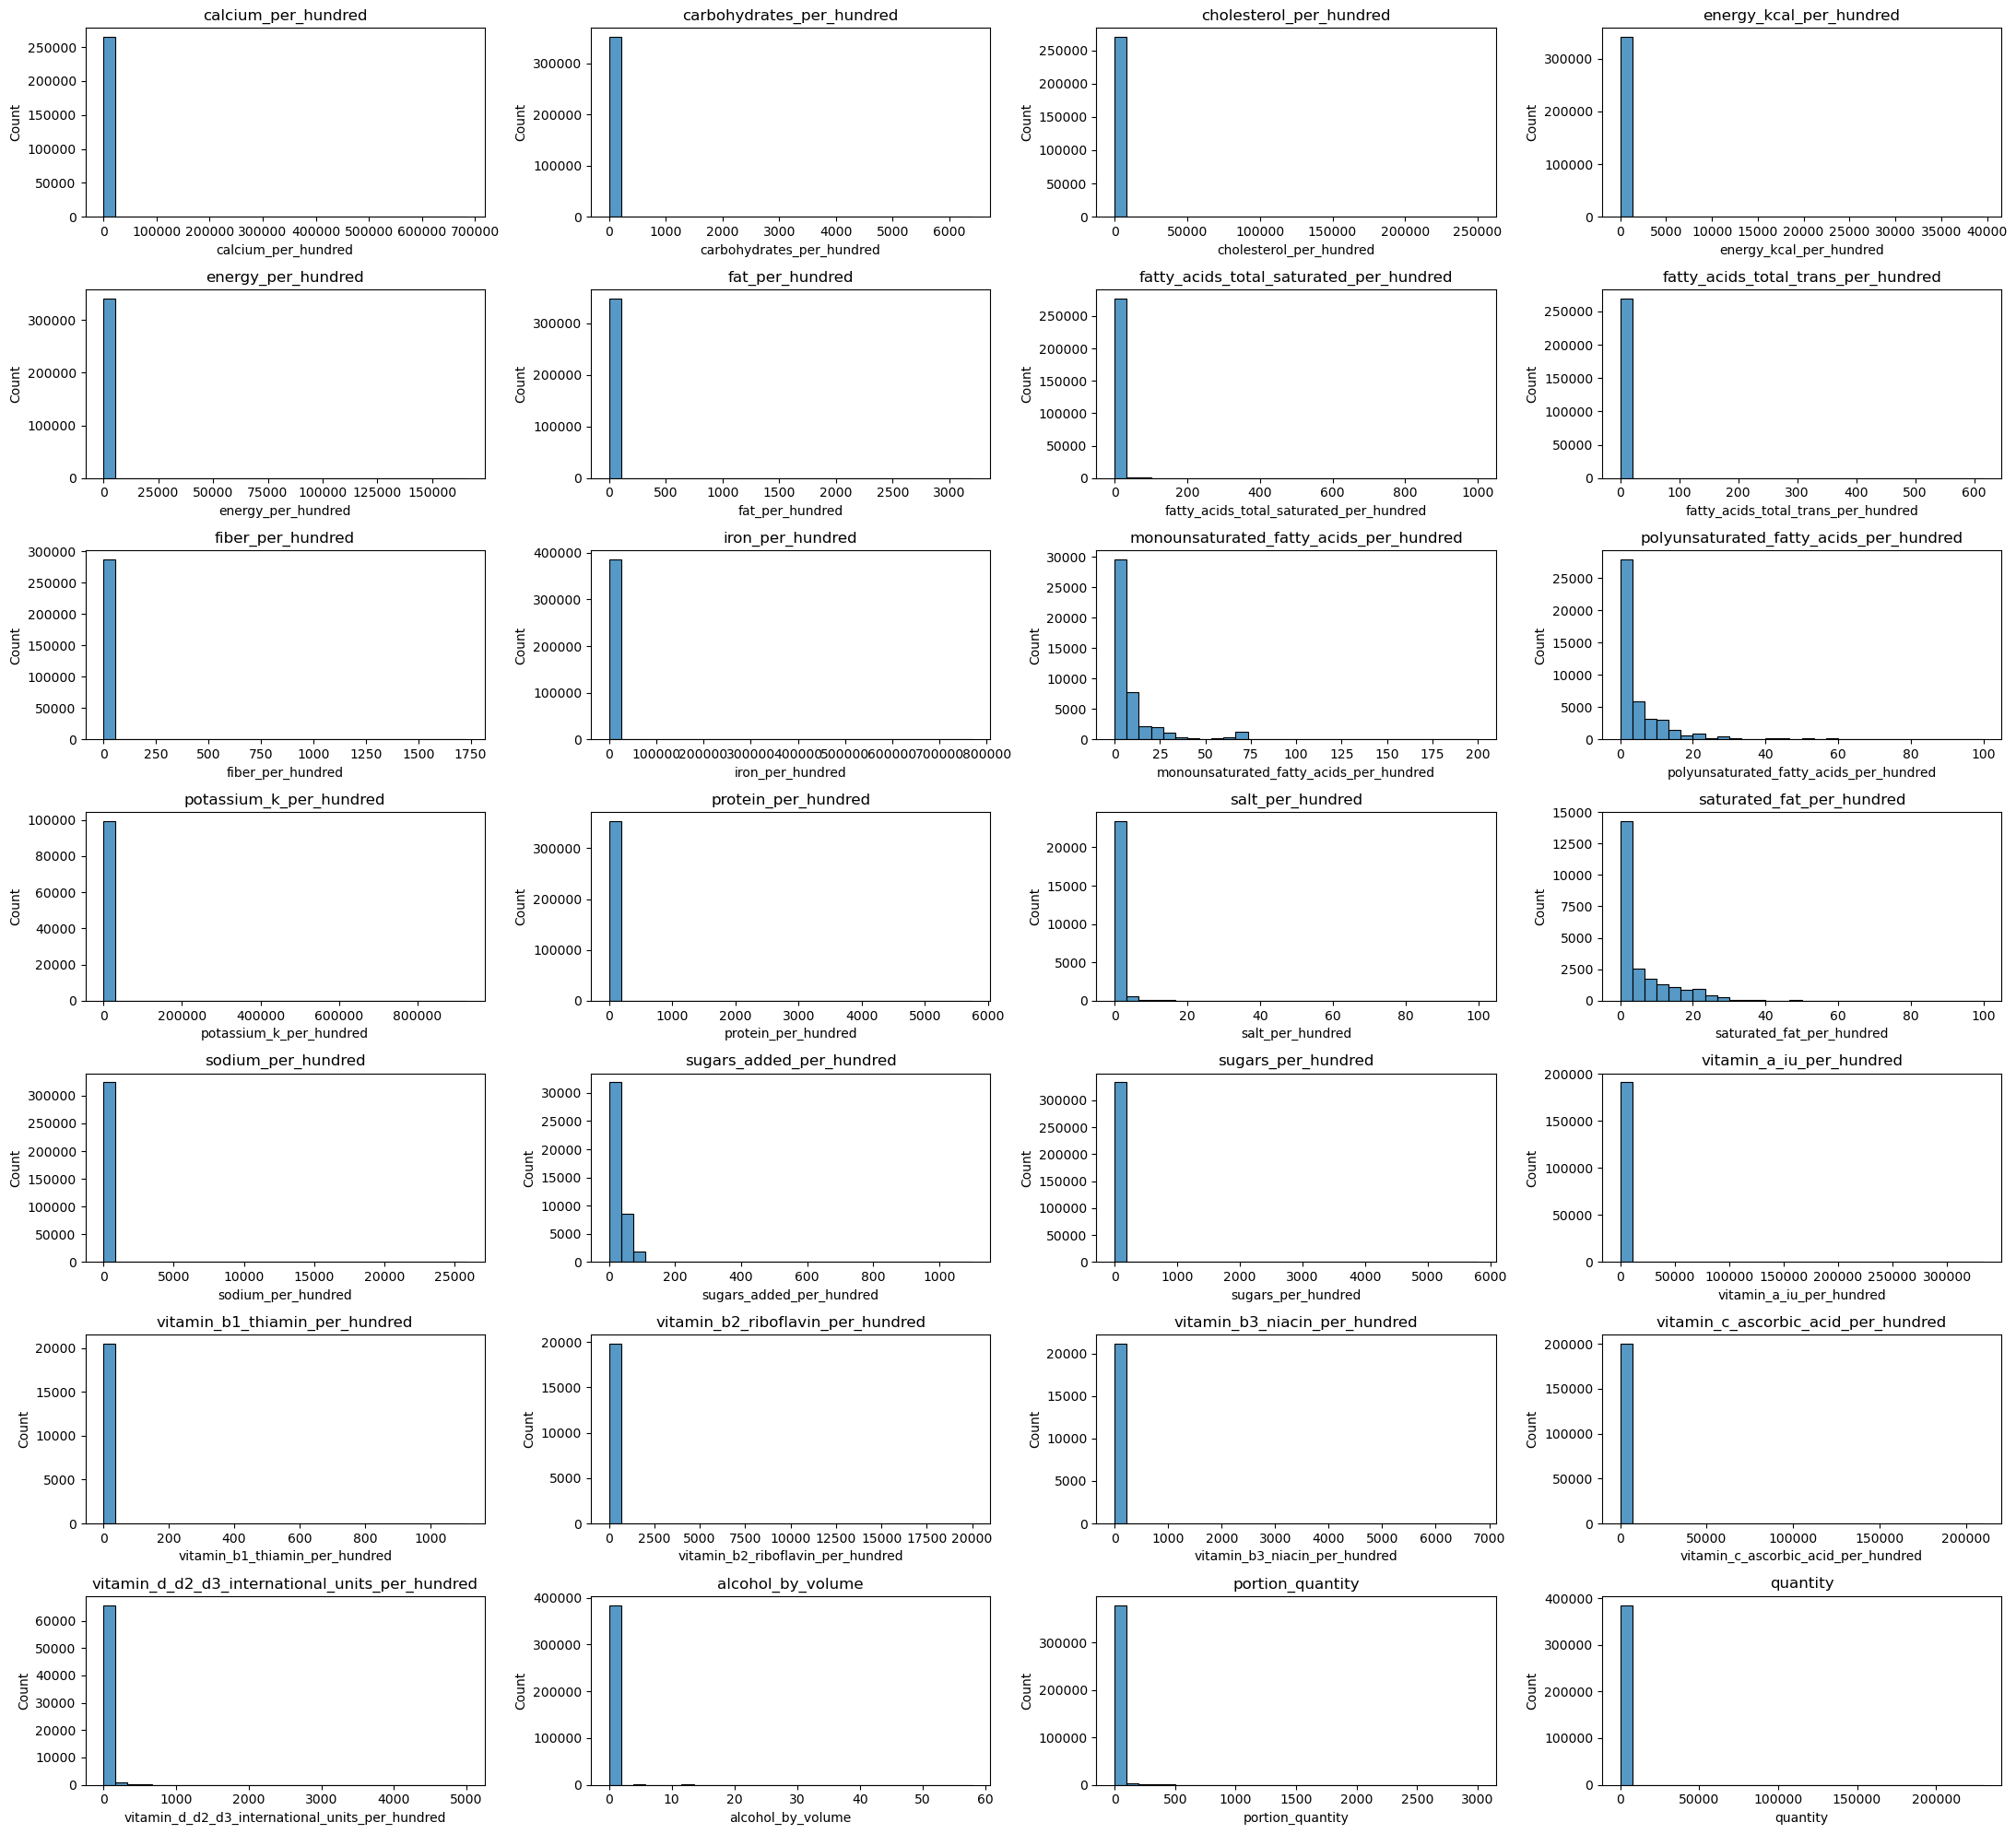

In [66]:
fig, axes = plt.subplots(7, 4, figsize=(22, 20))

for ax, col in zip(axes.flat, numerical_values.columns):
    sns.histplot(x=numerical_values[col], ax=ax, bins=30)
    ax.set_title(col)
    
plt.tight_layout()
plt.show()

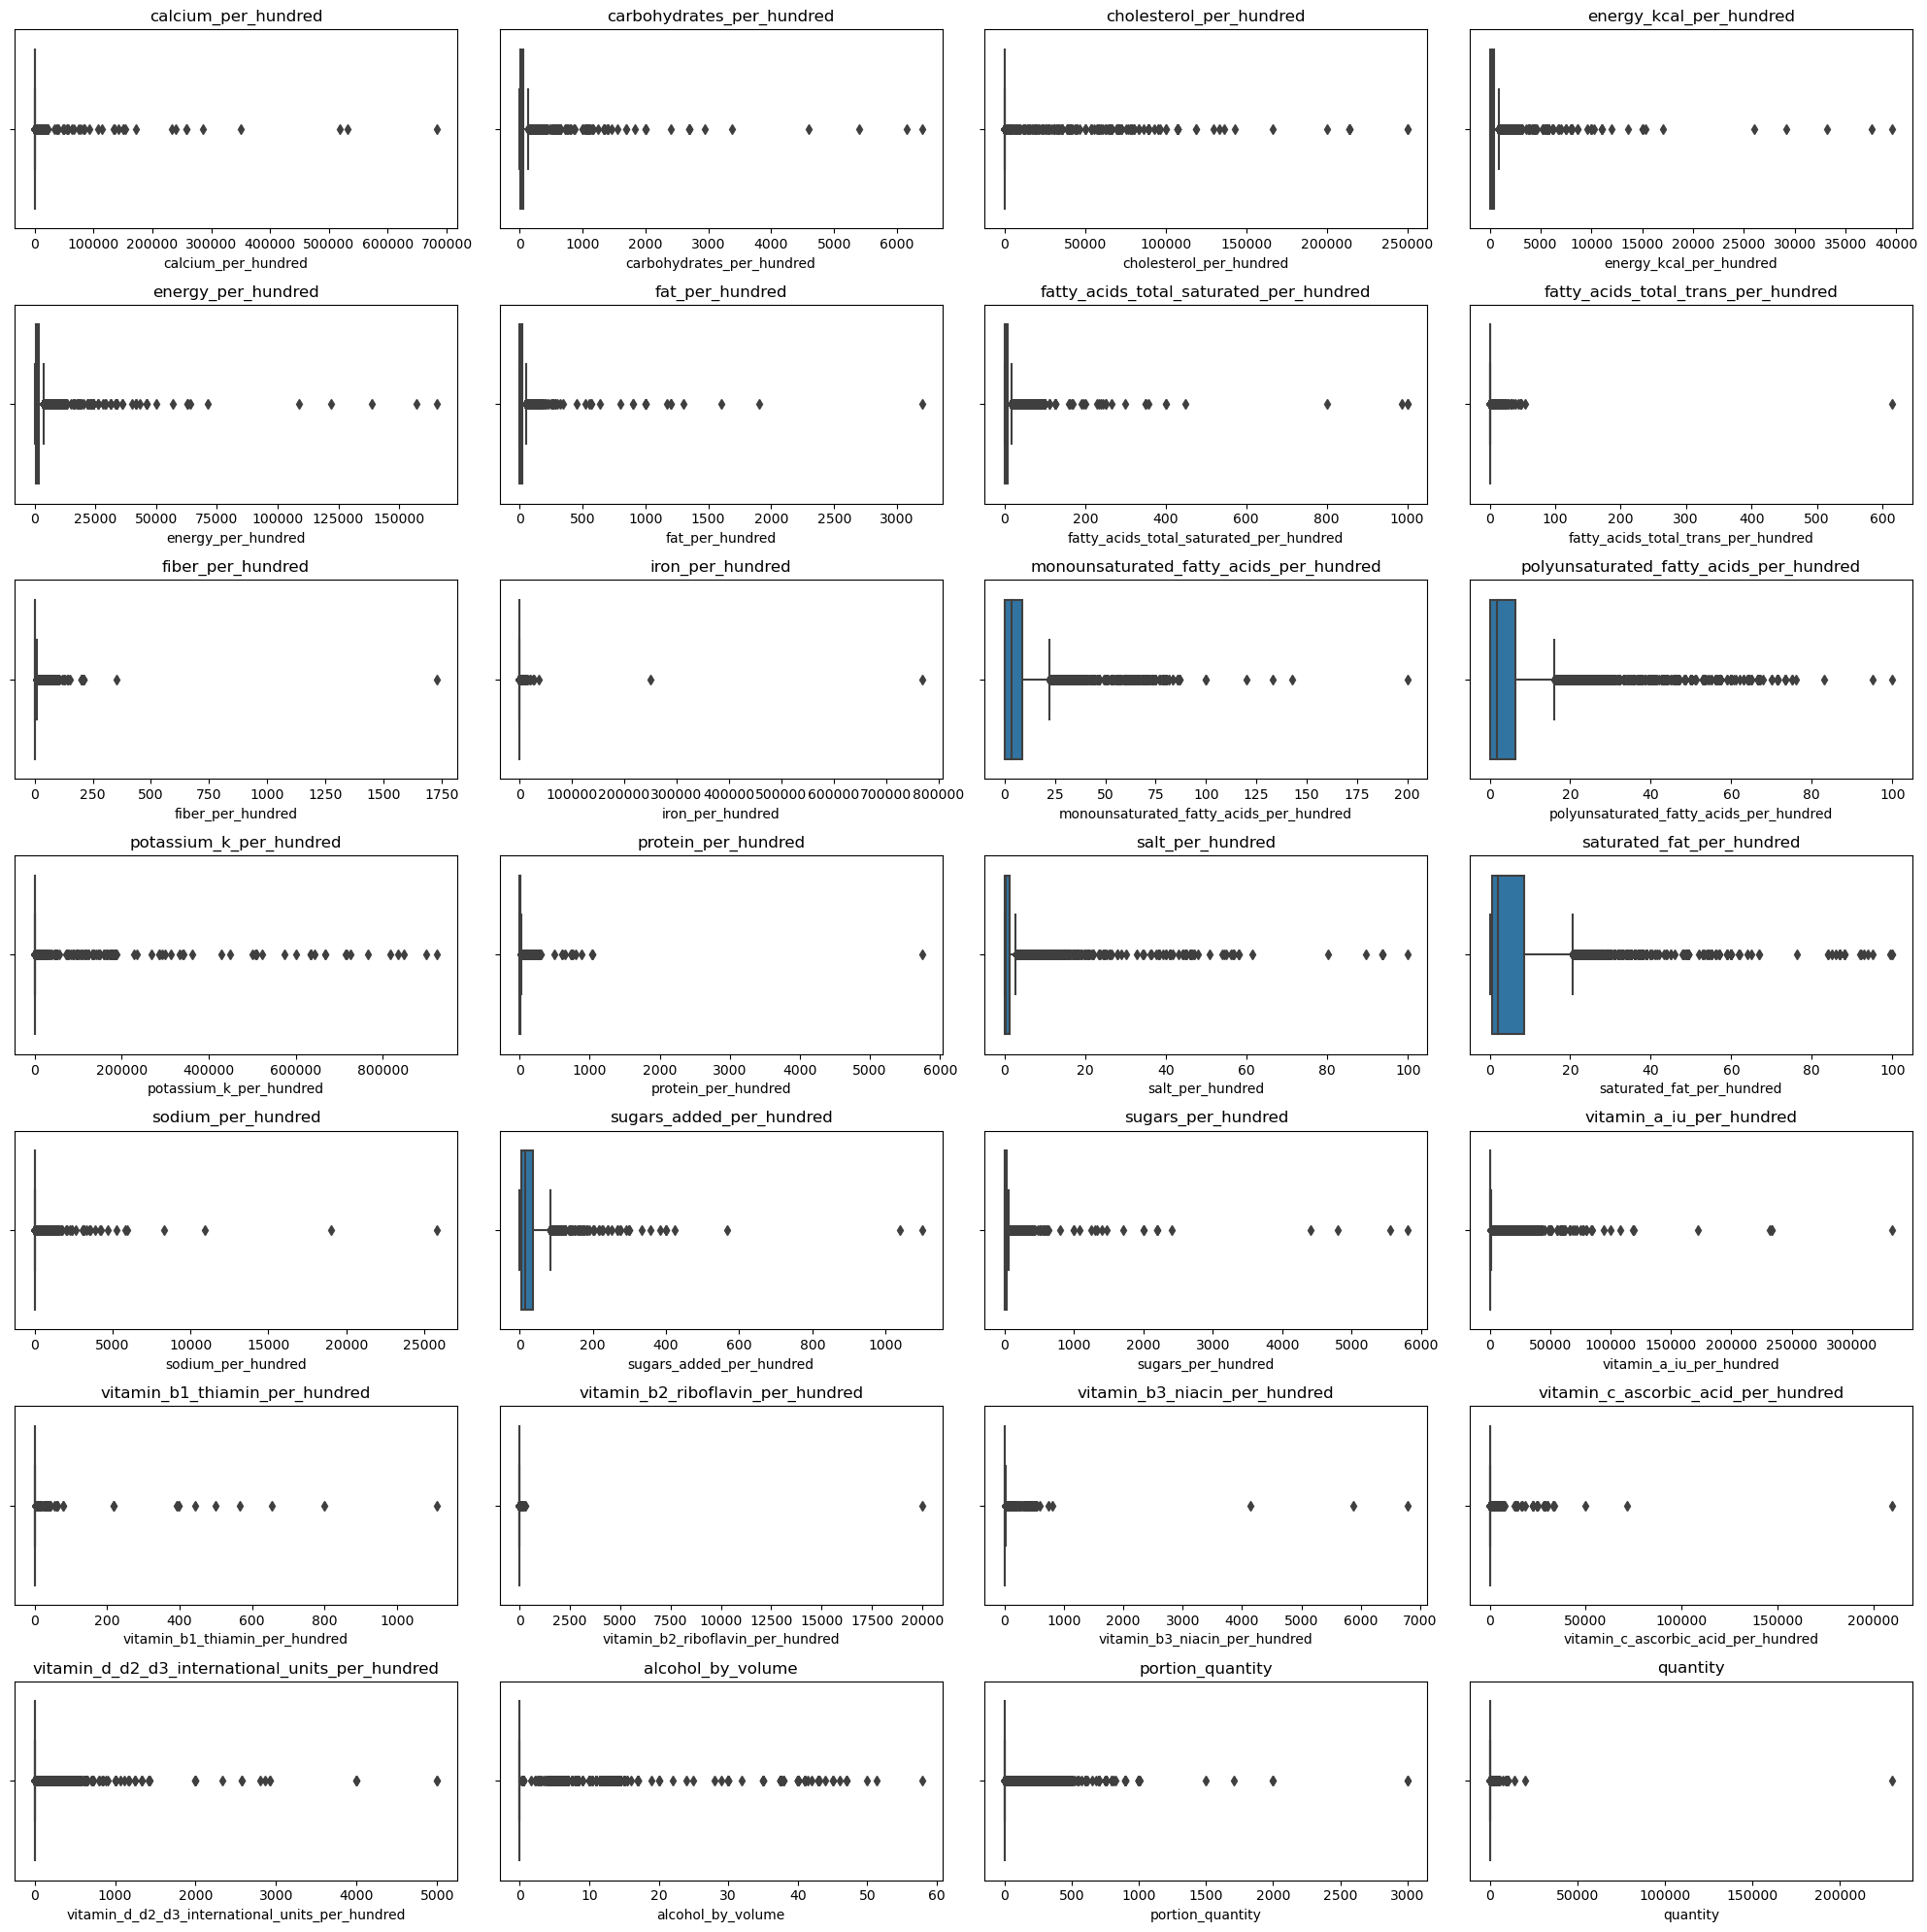

In [67]:
fig, axes = plt.subplots(7, 4, figsize=(20, 20))

for ax, col in zip(axes.flat, numerical_values.columns):
    sns.boxplot(x=numerical_values[col], ax=ax)
    ax.set_title(col)

plt.tight_layout()
plt.show()

<AxesSubplot:>

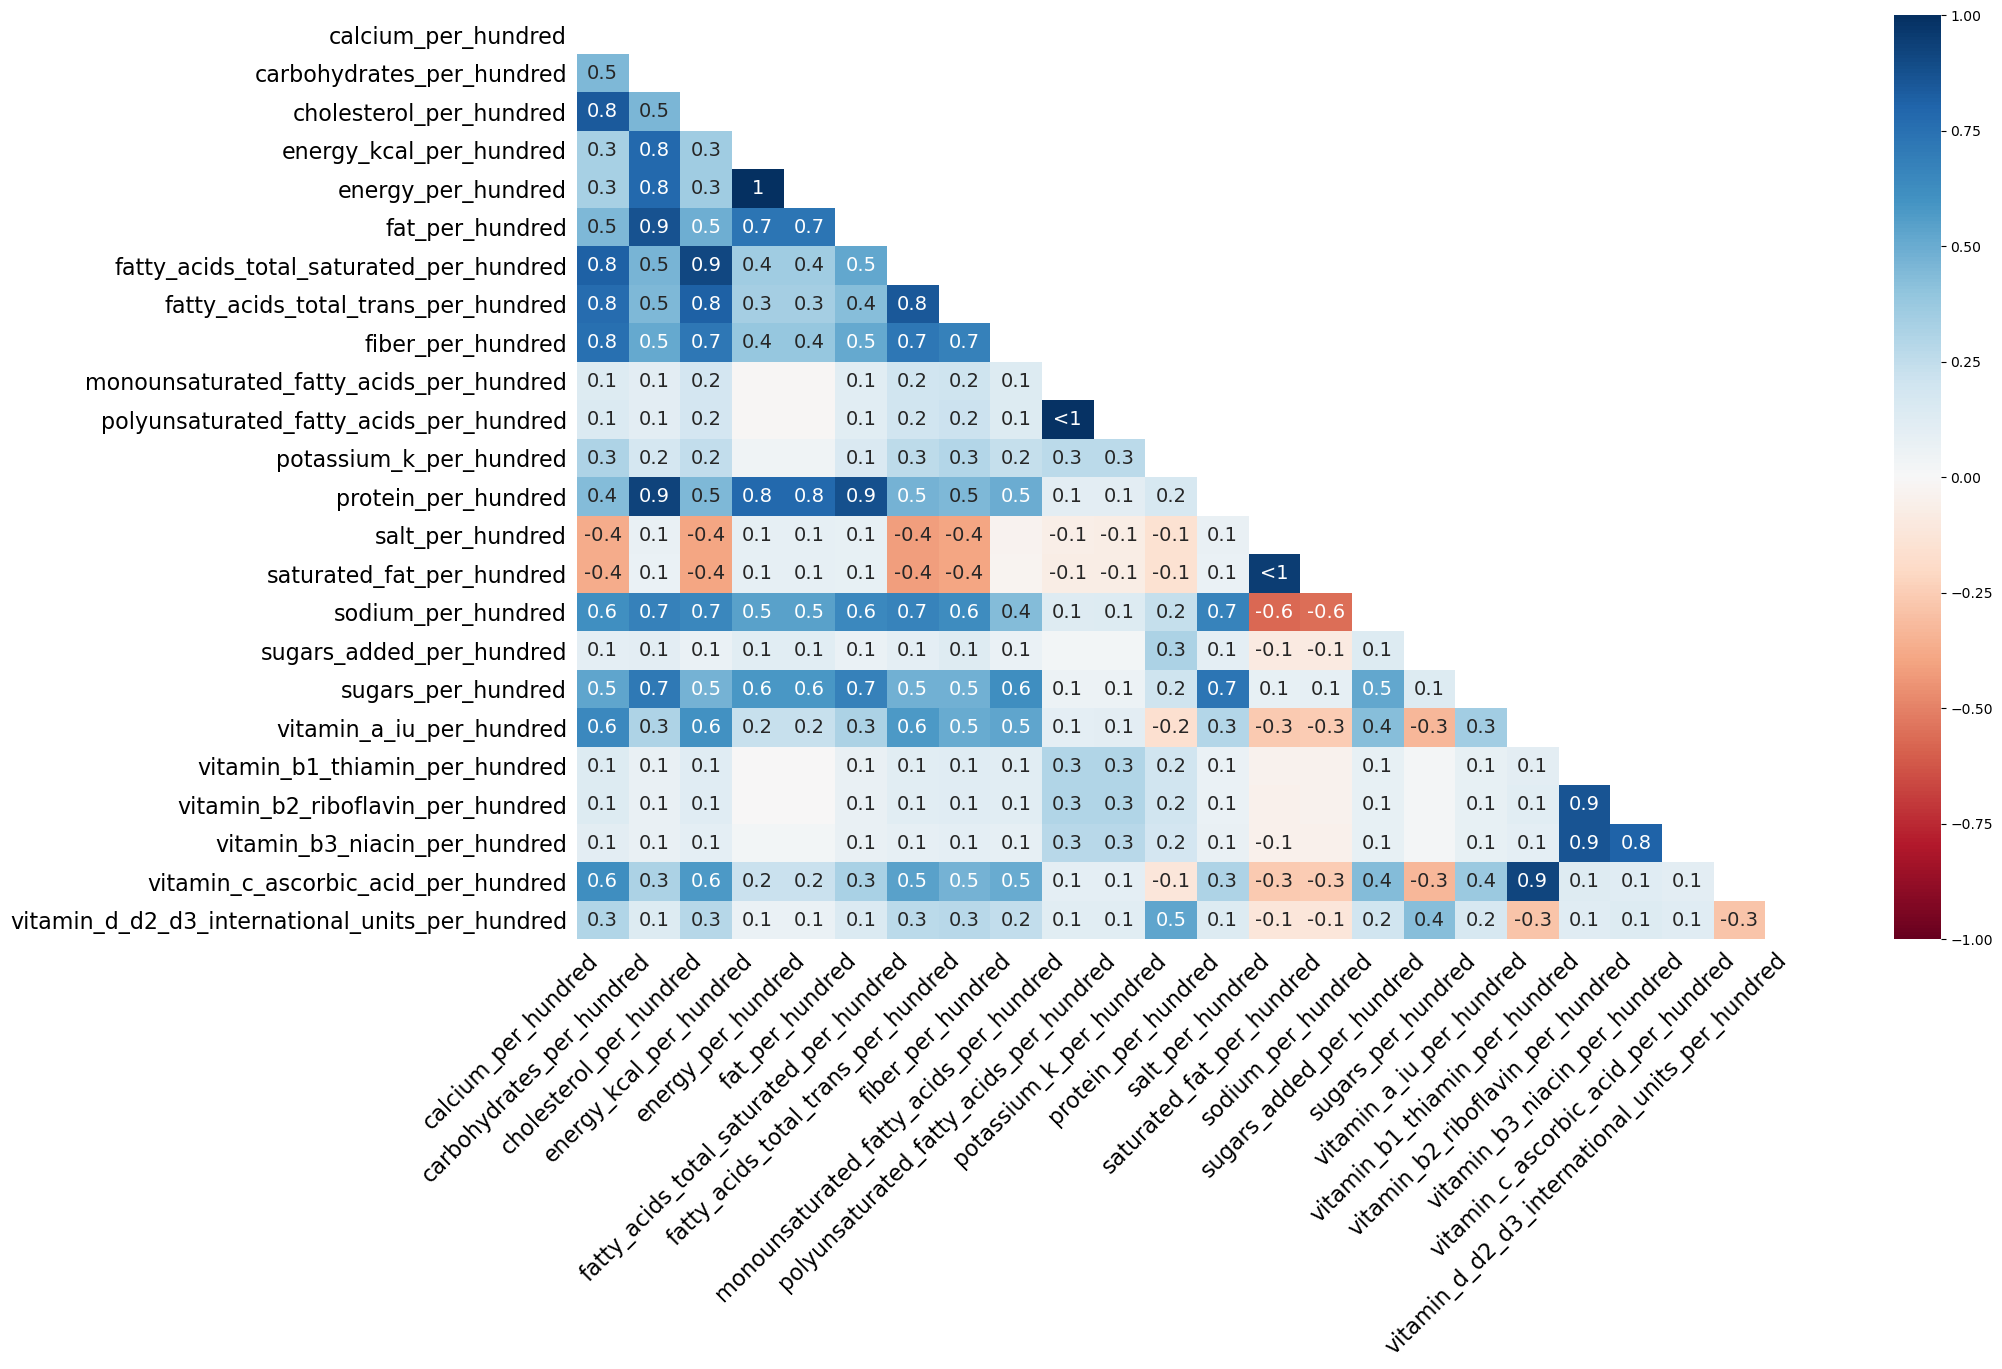

In [68]:
msno.heatmap(numerical_values)

The numerical values are right-skewed by looking at the histograms. Also looking at the `numerical_values.describe()` table it is understandable given the `max`, `mean`, `25%` and `75%`. On the other hand, the boxplots show a lot of outliers, which mostlikely are the ones mentioned in the statistical table as max. So a few bigger values that make the statistical analysis harder. Also the heatmap doesn't show any intresting possible good correlations that would be worth investigating. I think these bigger values need to be dropped in order to have a better idea about the distribution of the columns.

In [69]:
df_new

,calcium_per_hundred,carbohydrates_per_hundred,cholesterol_per_hundred,energy_kcal_per_hundred,energy_per_hundred,fat_per_hundred,fatty_acids_total_saturated_per_hundred,fatty_acids_total_trans_per_hundred,fiber_per_hundred,iron_per_hundred,...,created_at,id,ingredients_en,portion_quantity,product_name_de,product_name_en,product_name_fr,quantity,unit,updated_at
0,NaN,75.00,NaN,359.0,1500.0,0.42,NaN,NaN,NaN,0.0,...,2016-06-01T11:42:22.908Z,1000,Superior quality durum wheat Pasta\r\n\r\nIngr...,50.0,Bio Spaghetti,Bio Spaghetti,Spaghetti Bio,500.0,g,2019-10-30T13:46:32.651Z
1,NaN,1.50,NaN,242.0,1010.0,18.00,NaN,NaN,0.0,0.0,...,2016-06-01T11:42:25.111Z,1001,"Bio Milk (Switzerland), kitchen salt",75.0,Naturaplan Mozzarella,Naturaplan Mozzarella,Naturaplan Mozzarella,150.0,g,2019-10-30T13:47:12.174Z
2,NaN,52.68,NaN,325.0,1358.3,12.08,NaN,NaN,NaN,0.0,...,2016-06-01T11:42:25.900Z,1002,100% coffee Arabica,0.0,Caffè Mauro - Bio Kaffe,Caffè Mauro - Roasted organic coffee blend,Caffè Mauro - café bio,1000.0,g,2019-10-30T13:48:12.635Z
3,NaN,70.40,NaN,402.0,1679.0,7.90,NaN,NaN,9.1,0.0,...,2016-06-01T11:42:26.184Z,1003,"Powdered chocolate 99% (sugar, cocoa), emulsif...",17.0,Le chocolat Cailler - schokoladenpulver,Le chocolat Cailler - chocolate powder,Le chocolat Cailler - chocolat en poudre,500.0,g,2019-10-30T13:49:49.816Z
4,NaN,37.00,NaN,591.0,2470.0,44.00,NaN,NaN,9.0,0.0,...,2016-06-01T11:42:26.350Z,1004,"cocoa paste * (Honduras), raw cane sugar * (Pa...",20.0,Naturaplan ExtraDunkle Schokolade 70%,Naturaplan Extra Dark Chocolate 70%,Naturaplan Chocolat extra noir 70%,100.0,g,2019-10-30T13:50:42.826Z
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
385379,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.0,...,2021-10-04T14:08:42.215Z,376939,ingredient_missing,0.0,Nutriathletic - Whey (Swiss chocolate flavour),Nutriathletic - Whey (Swiss chocolate flavour),Nutriathletic - Whey (Swiss chocolate flavour),800.0,g,2021-10-04T14:12:00.863Z
385380,850.0,48.60,NaN,285.0,1210.0,0.05,NaN,NaN,NaN,0.0,...,2021-10-04T14:12:06.476Z,376940,ingredient_missing,20.0,Bourquin nutrition - Sportgetränk (Zitronenges...,Bourquin nutrition - Boisson d'effort (Goût ci...,Bourquin nutrition - Boisson d'effort (Goût ci...,480.0,g,2021-10-04T14:21:57.692Z
385381,NaN,22.00,NaN,584.0,2418.0,46.00,NaN,NaN,NaN,0.0,...,2021-10-04T14:22:10.685Z,376941,"cocoa mass, fat reduced cocoa, cocoa butter, d...",0.0,Lindt - Noir puissant 85% cacao,Lindt - Noir puissant 85% cacao,Lindt - Noir puissant 85% cacao,100.0,g,2021-10-04T14:27:23.319Z
385382,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.0,...,2021-10-04T14:27:36.157Z,376942,ingredient_missing,0.0,NaN,NaN,NaN,0.0,?,2021-10-04T14:27:43.384Z


3. **Errors and unrealistic values:**

In [70]:
df_filtered = df_new.copy()

In [71]:
cols_per_hundred = df_filtered.filter(regex="_per_hundred$").columns
cols_per_unit = [col.replace("_per_hundred", "_unit") for col in cols_per_hundred]

In [72]:
mask_g = ((df_filtered[cols_per_unit].to_numpy() == "g") & (df_filtered[cols_per_hundred].to_numpy()>100)).any(axis=1)
df_filtered.drop(df_filtered.index[mask_g], inplace=True)
mask_mg = ((df_filtered[cols_per_unit].to_numpy() == "mg") & (df_filtered[cols_per_hundred].to_numpy()>(10**5))).any(axis=1)
df_filtered.drop(df_filtered.index[mask_mg], inplace=True)
mask_µg = ((df_filtered[cols_per_unit].to_numpy() == "µg") & (df_filtered[cols_per_hundred].to_numpy()>(10**8))).any(axis=1)
df_filtered.drop(df_filtered.index[mask_µg], inplace=True)
mask_kJ = ((df_filtered[cols_per_unit].to_numpy() == "kJ") & (df_filtered[cols_per_hundred].to_numpy()>3700)).any(axis=1)
df_filtered.drop(df_filtered.index[mask_kJ], inplace=True)
mask_kCal = ((df_filtered[cols_per_unit].to_numpy() == "kCal") & (df_filtered[cols_per_hundred].to_numpy()>885)).any(axis=1)
df_filtered.drop(df_filtered.index[mask_kCal], inplace=True)
mask_ml = ((df_filtered[cols_per_unit].to_numpy() == "ml") & (df_filtered[cols_per_hundred].to_numpy()>(10**5))).any(axis=1)
df_filtered.drop(df_filtered.index[mask_ml], inplace=True)
mask_dl = ((df_filtered[cols_per_unit].to_numpy() == "dl") & (df_filtered[cols_per_hundred].to_numpy()>(10**(-1)))).any(axis=1)
df_filtered.drop(df_filtered.index[mask_dl], inplace=True)
mask_kg = ((df_filtered[cols_per_unit].to_numpy() == "kg") & (df_filtered[cols_per_hundred].to_numpy()>(10**(-3)))).any(axis=1)
df_filtered.drop(df_filtered.index[mask_kg], inplace=True)

#Not sure about these last two
mask_va = ((df_filtered["vitamin_a_iu_unit"].to_numpy() == "IU") & (df_filtered["vitamin_a_iu_per_hundred"].to_numpy()>(3.3*(10**8))))
df_filtered.drop(df_filtered.index[mask_va], inplace=True)
mask_vd = ((df_filtered["vitamin_d_d2_d3_international_units_unit"].to_numpy() == "IU") & (df_filtered["vitamin_d_d2_d3_international_units_per_hundred"].to_numpy()>(4*(10**9))))
df_filtered.drop(df_filtered.index[mask_vd], inplace=True)

In [73]:
df_filtered.shape

(383217, 77)

In [74]:
numerical_values_filtered = df_filtered.loc[:, df_filtered.dtypes == "float64"]

In [106]:
numerical_values_filtered.describe()

,calcium_per_hundred,carbohydrates_per_hundred,cholesterol_per_hundred,energy_kcal_per_hundred,energy_per_hundred,fat_per_hundred,fatty_acids_total_saturated_per_hundred,fatty_acids_total_trans_per_hundred,fiber_per_hundred,iron_per_hundred,...,sugars_per_hundred,vitamin_a_iu_per_hundred,vitamin_b1_thiamin_per_hundred,vitamin_b2_riboflavin_per_hundred,vitamin_b3_niacin_per_hundred,vitamin_c_ascorbic_acid_per_hundred,vitamin_d_d2_d3_international_units_per_hundred,alcohol_by_volume,portion_quantity,quantity
count,264363.000000,349508.000000,269465.000000,339686.000000,339688.000000,347187.000000,278105.000000,268348.000000,285831.000000,383217.000000,...,331572.000000,191859.000000,20369.000000,19643.000000,21085.000000,199867.000000,66906.000000,383217.000000,383217.000000,383217.000000
mean,97.374106,33.220638,42.629489,267.502311,1119.040100,12.484281,4.847188,0.031786,2.881094,2.294499,...,16.554167,492.010768,0.922061,1.676363,9.794059,14.438695,13.999058,0.031707,4.197968,97.583841
std,520.437525,29.123182,1177.860192,187.783213,785.346953,16.653615,7.112204,0.475581,4.565264,105.046583,...,21.375198,2431.703576,13.500617,142.755329,73.105981,344.170446,70.238439,0.798628,33.134716,401.300970
min,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,0.000000,6.670000,0.000000,89.000000,372.380000,0.000000,0.000000,0.000000,0.000000,0.000000,...,1.670000,0.000000,0.000000,0.200000,3.000000,0.000000,0.000000,0.000000,0.000000,28.000000
50%,36.000000,23.330000,0.000000,266.000000,1112.940000,5.380000,1.980000,0.000000,1.530000,0.000000,...,6.450000,0.000000,0.000000,0.330000,4.880000,0.000000,0.000000,0.000000,0.000000,44.000000
75%,102.000000,59.520000,24.000000,400.000000,1673.600000,20.000000,7.140000,0.000000,3.600000,1.590000,...,25.000000,352.000000,1.000000,0.570000,8.240000,3.900000,0.000000,0.000000,0.000000,120.000000
max,93750.000000,100.000000,100000.000000,885.000000,3700.000000,100.000000,100.000000,53.570000,100.000000,26666.670000,...,100.000000,333333.000000,1111.000000,20000.000000,6785.710000,71428.600000,5000.000000,57.900000,3000.000000,230000.000000


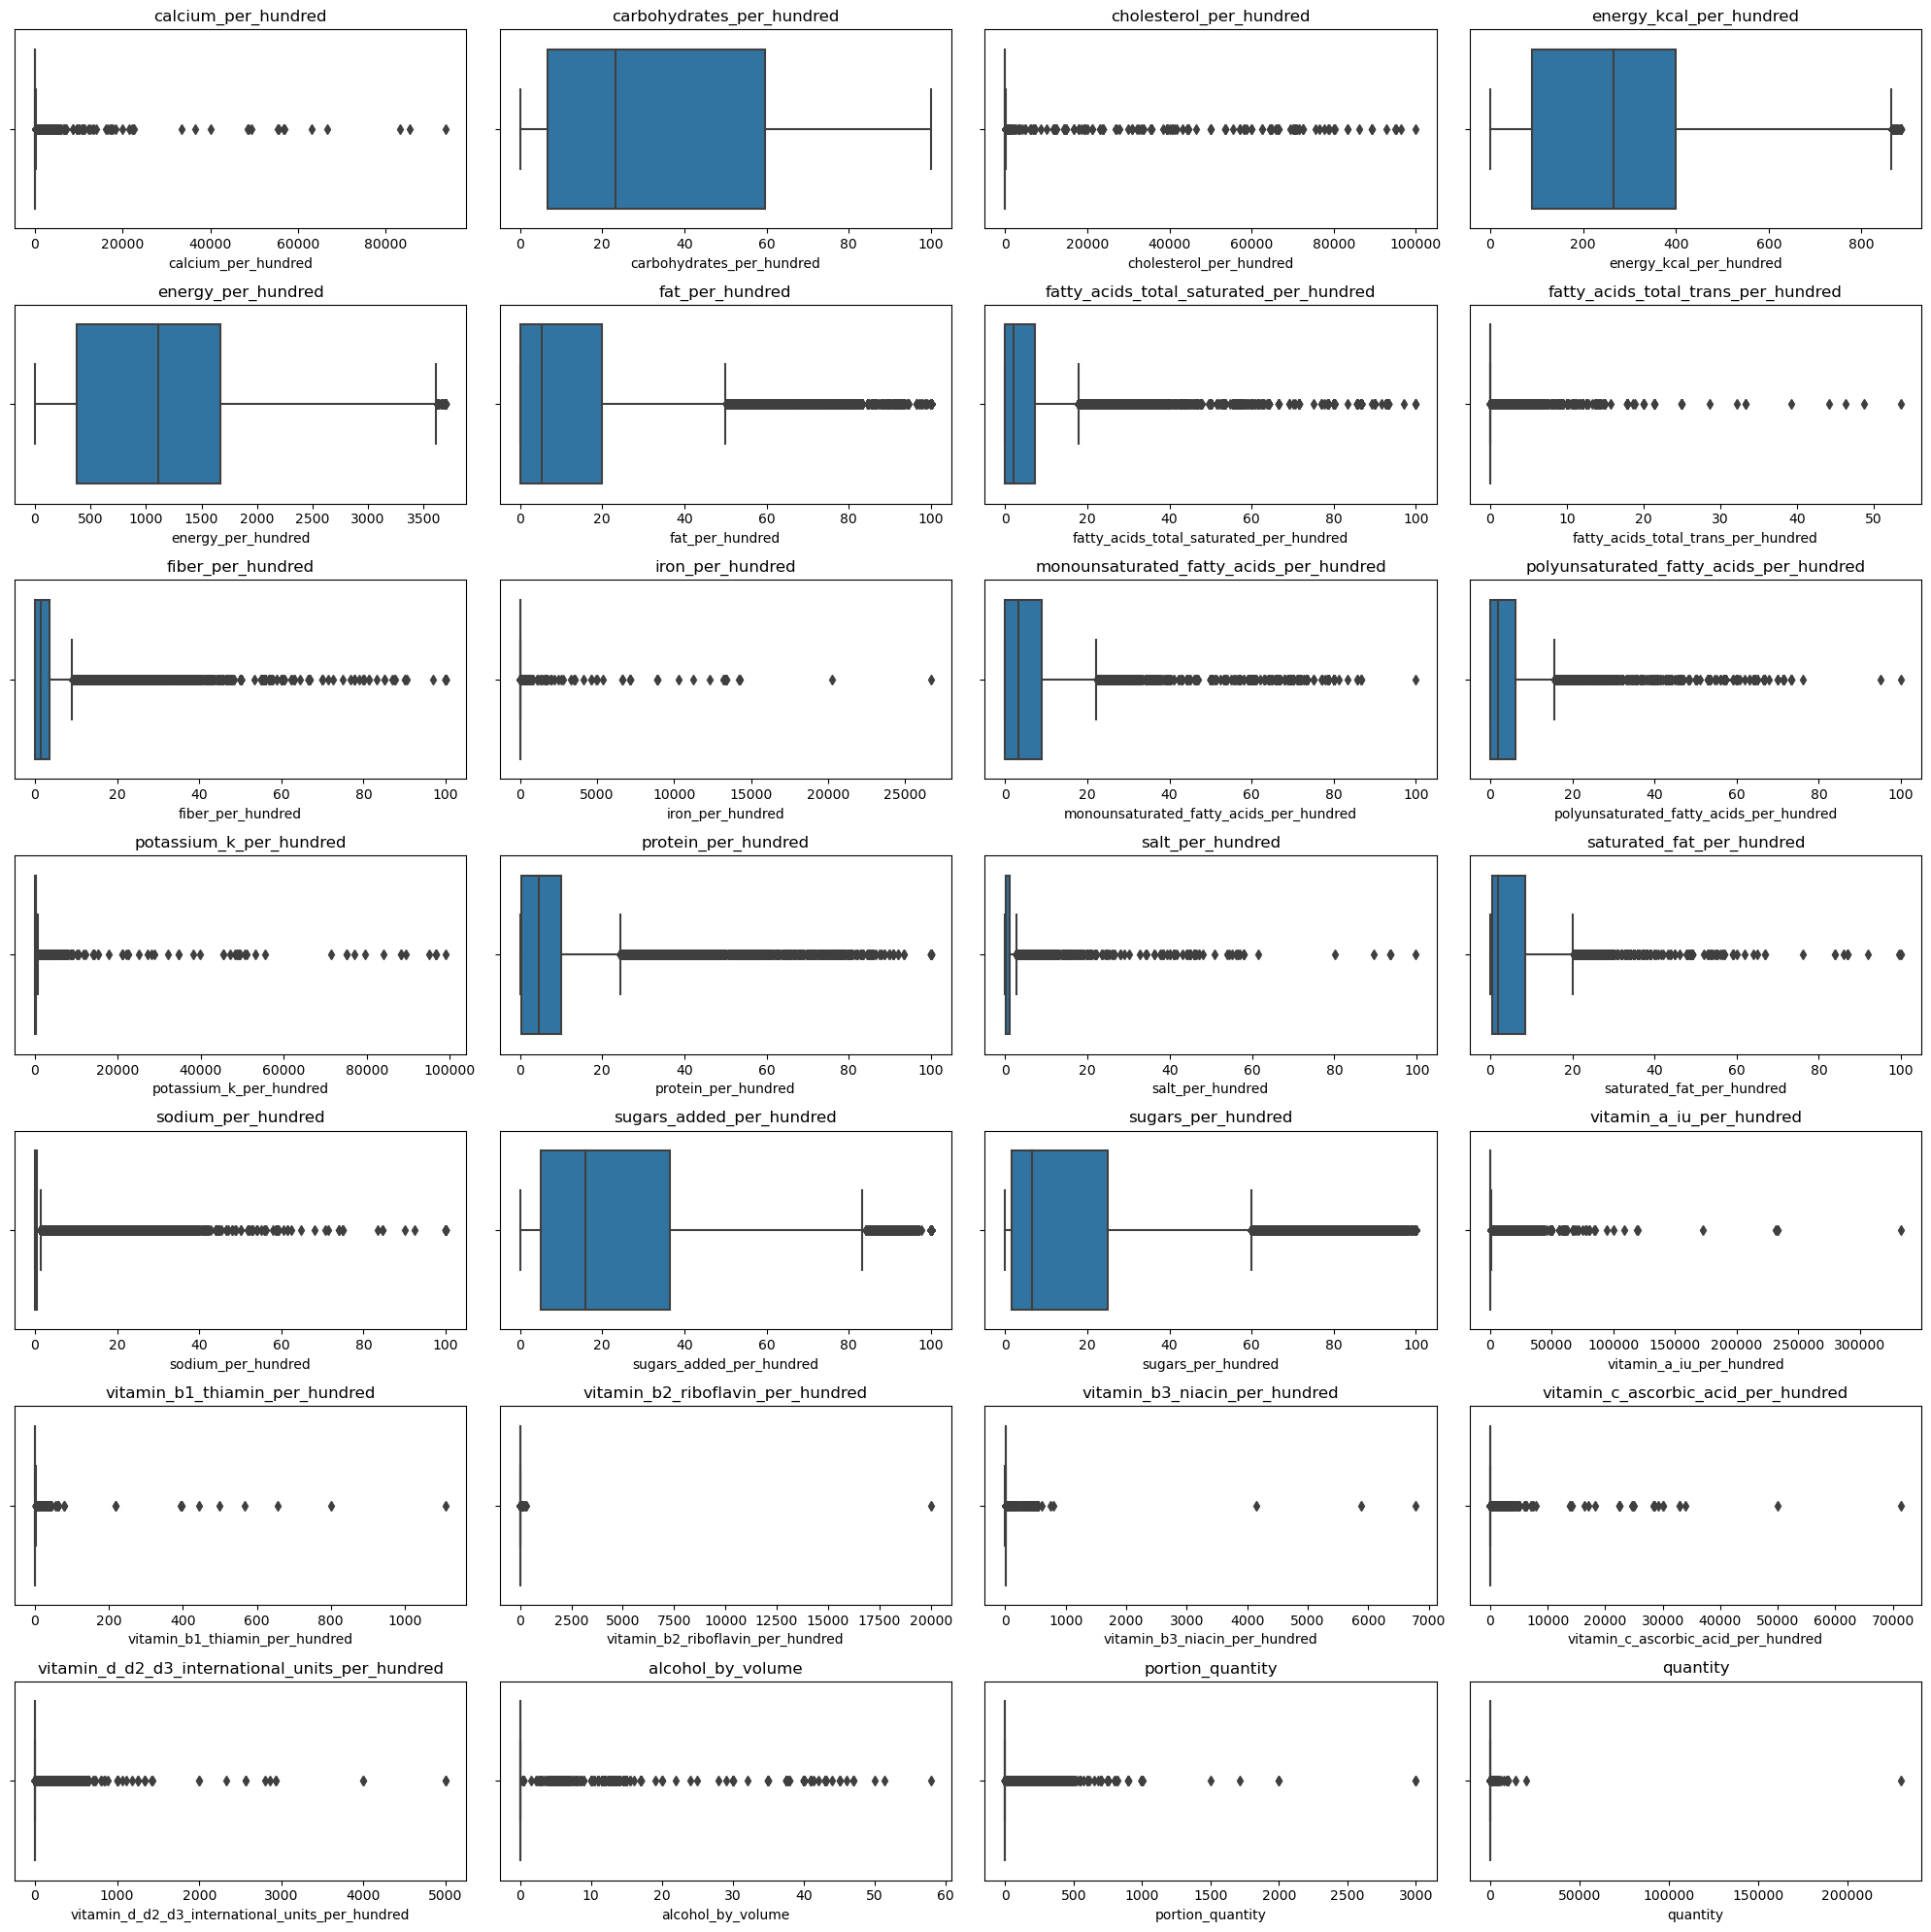

In [75]:
fig, axes = plt.subplots(7, 4, figsize=(20, 20))

for ax, col in zip(axes.flat, numerical_values_filtered.columns):
    sns.boxplot(x=numerical_values_filtered[col], ax=ax)
    ax.set_title(col)

plt.tight_layout()
plt.show()

After filltering the data using units, the box plots are more readable in a lot of columns and we have taking out a lot of outliers. 2167 rows were dropped.

4. **Columns investigation:**

   a. **Macronutrients check:**

As metionned in the comments of the assignment and according to google, the fiber count is included in the carbohydrates in the US. In this case, to check the macronutrients total count it's better to filter the US while doing it.

In [76]:
nutri_cols_US = ["fat_per_hundred", "carbohydrates_per_hundred", "protein_per_hundred"]
nutri_cols = ["fat_per_hundred", "carbohydrates_per_hundred", "protein_per_hundred", "fiber_per_hundred"]
df_filtered["nutri_total"] = df_filtered[nutri_cols].sum(axis=1)
usa_nutri = df_filtered["country"] == "US"
df_filtered.loc[usa_nutri, "nutri_total"] = df_filtered.loc[usa_nutri, nutri_cols_US].sum(axis=1)

In [77]:
df_filtered["nutri_total"][df_filtered["nutri_total"]>100].count()

2883

The number of products with a total of macronutients over 100g without separating the US and including the fiber was around 28k. And without separting the US but not including the fiber, the total count was 2667. Now after calculating the US separatly without the fiber but including it for the rest of the countries the number of products that don't respect the 100g limit are 2883.

In [78]:
mask_nutri = df_filtered["nutri_total"]>100
df_filtered.drop(df_filtered.index[mask_nutri], inplace=True)

In [154]:
df_filtered = df_filtered.drop("nutri_total", axis=1)

In [155]:
df_filtered.shape

(379553, 77)

   b. **Energy kJ & kcal check:**

As seen in the exercise 9 of the 03.Cleaning data course 1 calorie (kCal) = 4.184 kilojoules (kJ). Let's check of the conversion is done right between the two columns.

In [80]:
df_energy = df_filtered[["energy_per_hundred", "energy_kcal_per_hundred"]].copy()
df_energy["coefficient_kcaltokJ"] = df_filtered["energy_per_hundred"] / df_filtered["energy_kcal_per_hundred"]
df_energy

,energy_per_hundred,energy_kcal_per_hundred,coefficient_kcaltokJ
0,1500.0,359.0,4.178273
1,1010.0,242.0,4.173554
2,1358.3,325.0,4.179385
3,1679.0,402.0,4.176617
4,2470.0,591.0,4.179357
...,...,...,...
385378,858.0,206.0,4.165049
385379,NaN,NaN,NaN
385381,2418.0,584.0,4.140411
385382,NaN,NaN,NaN


In [81]:
df_energy["coefficient_kcaltokJ"].max()

inf

In [82]:
df_energy["coefficient_kcaltokJ"].min()

0.23333333333333334

In [83]:
df_energy["coefficient_kcaltokJ"][round(df_energy["coefficient_kcaltokJ"],3)>4.184].count()

14530

In [84]:
df_energy["coefficient_kcaltokJ"][round(df_energy["coefficient_kcaltokJ"],3)<4.184].count()

13110

As you can see there is a lot of rows that don't respect the mathematical conversion ratio. This can be due to the rounding regulations in different countries. In the EU this margin is maxed at 0.5%, however in other countries it can reach up to 4%.

In [85]:
df_energy["coefficient_kcaltokJ"][round(df_energy["coefficient_kcaltokJ"],5)>4.35136].count()

435

In [86]:
df_energy["coefficient_kcaltokJ"][round(df_energy["coefficient_kcaltokJ"],5)<4.01664].count()

346

Taking into consideration the 4% margin, we can see that there is 781 values who are out of this range.

In [87]:
List_energy_index = df_energy.loc[(df_energy["coefficient_kcaltokJ"].round(5)>4.35136)| (df_energy["coefficient_kcaltokJ"].round(5)<4.01664)].index

In [88]:
df_filtered.drop(index=List_energy_index, inplace=True)

In [89]:
df_filtered.shape

(379553, 78)

   c. **Macronutrients' energy content:**

In [156]:
df_energy_content= df_filtered[["product_name_en","fat_per_hundred", "carbohydrates_per_hundred", "protein_per_hundred", "fiber_per_hundred", "energy_per_hundred"]].copy()

In [157]:
df_energy_content["fat_energy"] = 37*df_energy_content["fat_per_hundred"]
df_energy_content["carbohydrates_energy"] = 17*df_energy_content["carbohydrates_per_hundred"]
df_energy_content["protein_energy"] = 17*df_energy_content["protein_per_hundred"]
df_energy_content["fiber_energy"] = 8*df_energy_content["fiber_per_hundred"]
df_energy_content["Total_energy"] = df_energy_content["fiber_energy"] + df_energy_content["protein_energy"] + df_energy_content["carbohydrates_energy"] + df_energy_content["fat_energy"]
df_energy_content["diff_energy"] = (df_energy_content["Total_energy"] - df_energy_content["energy_per_hundred"]).abs()
df_energy_content

,product_name_en,fat_per_hundred,carbohydrates_per_hundred,protein_per_hundred,fiber_per_hundred,energy_per_hundred,fat_energy,carbohydrates_energy,protein_energy,fiber_energy,Total_energy,diff_energy
0,Bio Spaghetti,0.42,75.00,11.00,NaN,1500.0,15.54,1275.00,187.00,NaN,NaN,NaN
1,Naturaplan Mozzarella,18.00,1.50,19.00,0.0,1010.0,666.00,25.50,323.00,0.0,1014.5,4.5
2,Caffè Mauro - Roasted organic coffee blend,12.08,52.68,19.05,NaN,1358.3,446.96,895.56,323.85,NaN,NaN,NaN
3,Le chocolat Cailler - chocolate powder,7.90,70.40,6.80,9.1,1679.0,292.30,1196.80,115.60,72.8,1677.5,1.5
4,Naturaplan Extra Dark Chocolate 70%,44.00,37.00,8.00,9.0,2470.0,1628.00,629.00,136.00,72.0,2465.0,5.0
...,...,...,...,...,...,...,...,...,...,...,...,...
385378,falafel (patate douce),13.00,17.00,4.30,NaN,858.0,481.00,289.00,73.10,NaN,NaN,NaN
385379,Nutriathletic - Whey (Swiss chocolate flavour),NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
385381,Lindt - Noir puissant 85% cacao,46.00,22.00,12.50,NaN,2418.0,1702.00,374.00,212.50,NaN,NaN,NaN
385382,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [137]:
df_energy_content["diff_energy"].max()

3700.0

In [138]:
df_energy_content["diff_energy"].min()

0.0

In [164]:
df_energy_content["diff_energy"][df_energy_content["diff_energy"]>1783].count()

56

In [140]:
df_energy_content.describe()

,fat_per_hundred,carbohydrates_per_hundred,protein_per_hundred,fiber_per_hundred,energy_per_hundred,fat_energy,carbohydrates_energy,protein_energy,fiber_energy,Total_energy,diff_energy
count,343562.000000,345872.000000,347919.000000,282609.000000,336063.000000,343562.000000,345872.000000,347919.000000,282609.000000,279255.000000,268391.000000
mean,12.344436,33.020865,7.089810,2.848641,1111.447161,456.744125,561.354711,120.526764,22.789132,1215.838252,68.719689
std,16.562777,29.050087,8.475441,4.503791,780.464267,612.822745,493.851472,144.082490,36.030326,765.939927,115.328590
min,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,0.000000,6.670000,0.420000,0.000000,372.380000,0.000000,113.390000,7.140000,0.000000,477.200000,11.600000
50%,5.360000,23.080000,4.500000,1.500000,1100.390000,198.320000,392.360000,76.500000,12.000000,1230.500000,32.710000
75%,20.000000,58.820000,10.000000,3.600000,1673.600000,740.000000,999.940000,170.000000,28.800000,1783.280000,81.610000
max,100.000000,100.000000,100.000000,100.000000,3700.000000,3700.000000,1700.000000,1700.000000,800.000000,3700.000000,3700.000000


In [128]:
df_energy_content["diff_energy"].idxmax()

84822

In [129]:
df_filtered[df_filtered.index == 84822]

,calcium_per_hundred,carbohydrates_per_hundred,cholesterol_per_hundred,energy_kcal_per_hundred,energy_per_hundred,fat_per_hundred,fatty_acids_total_saturated_per_hundred,fatty_acids_total_trans_per_hundred,fiber_per_hundred,iron_per_hundred,...,id,ingredients_en,portion_quantity,product_name_de,product_name_en,product_name_fr,quantity,unit,updated_at,nutri_total
84822,0.0,0.0,0.0,0.0,0.0,100.0,0.0,NaN,0.0,0.0,...,86589,"GARLIC, BLACK PEPPER, PARSLEY, SALT, TRICALCIU...",0.0,COMPLETE SEASONING,COMPLETE SEASONING,COMPLETE SEASONING,1.0,g,2021-04-26T10:19:45.572Z,100.0


This doesn't make sense. How can a "complete seasoing" with 0 `energy_per_hundred` contain 100 `fat_per_hundred`. Which is our max value in `diff_energy` which is the absolute value of the calculated energy minus the `energy_per_hundred`. 

Given the fact the 75% value of `energy_per_hundred` is 1674 and the 75% value of `Total_energy` is 1783 and since some values can be missing from either sides. I will be drop droping any `Total_energy` value superior than 1783.

In [167]:
List_energy_content_index = df_energy_content.loc[df_energy_content["diff_energy"]>1783].index

In [168]:
df_filtered.drop(index=List_energy_content_index, inplace=True)

In [169]:
df_filtered.shape

(379497, 77)

5. **List and address outliers:**

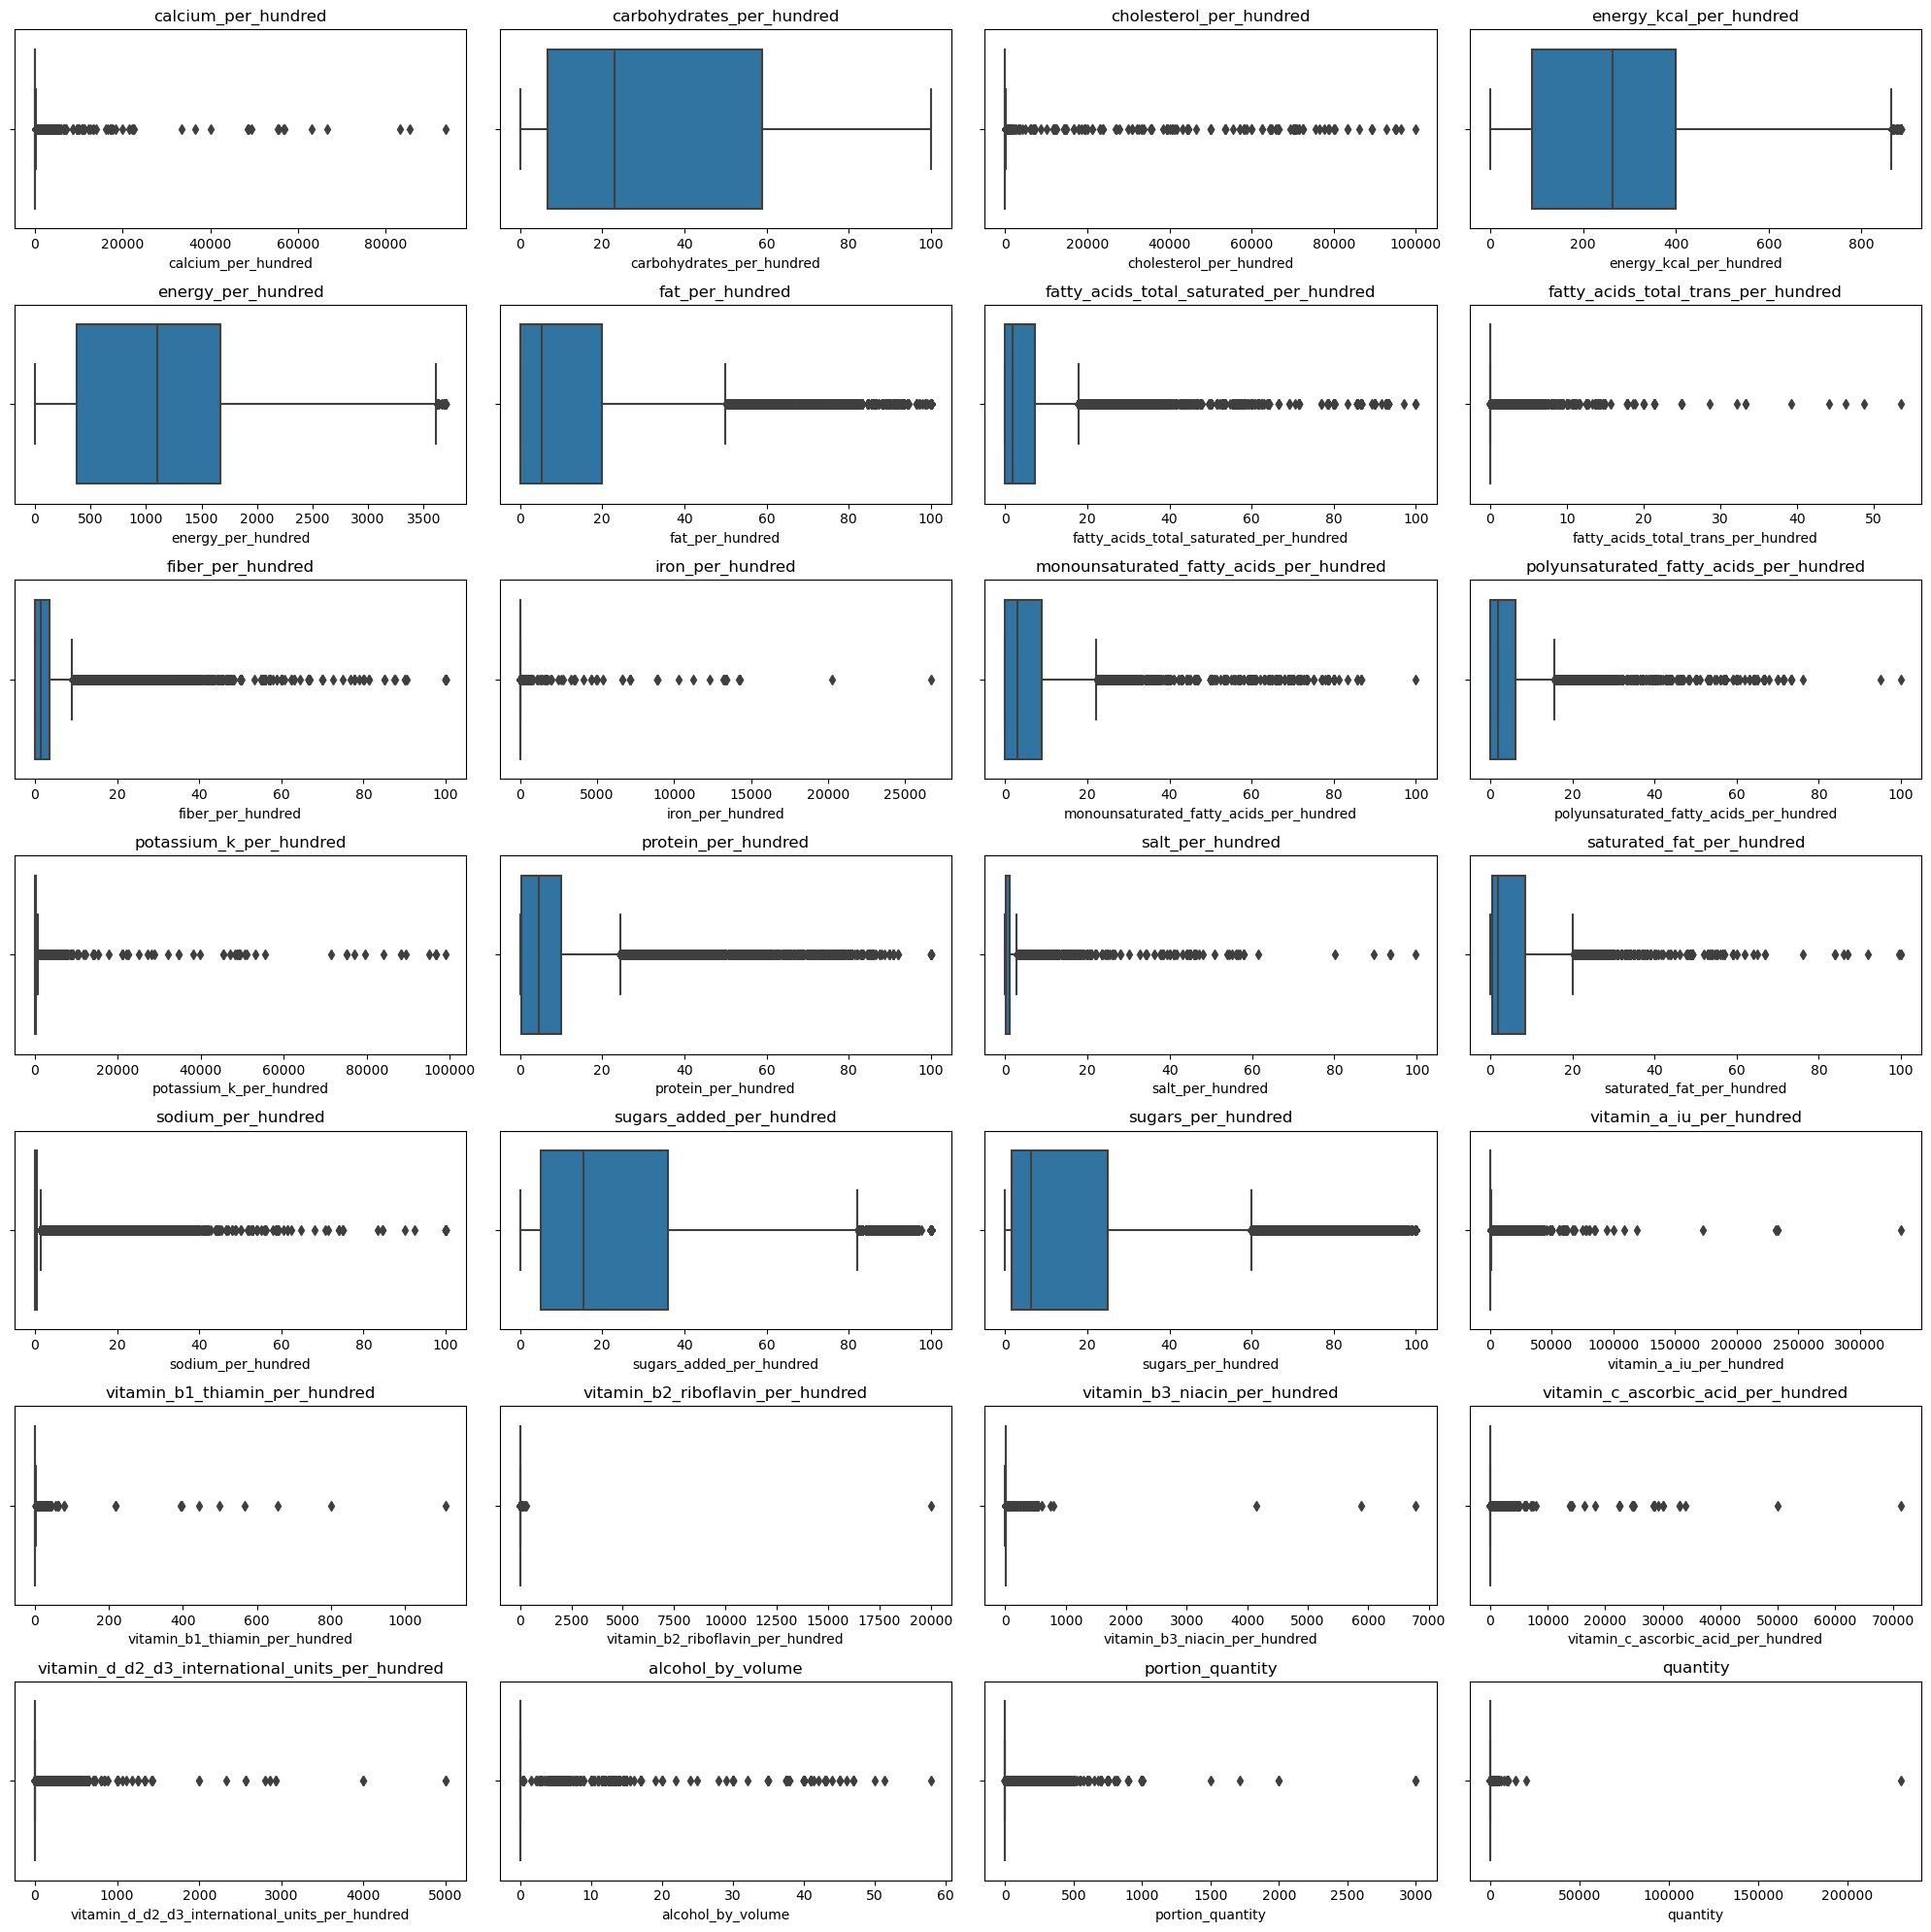

In [174]:
numerical_values_filtered = df_filtered.loc[:, df_filtered.dtypes == "float64"]
fig, axes = plt.subplots(7, 4, figsize=(20, 20))

for ax, col in zip(axes.flat, numerical_values_filtered.columns):
    sns.boxplot(x=numerical_values_filtered[col], ax=ax)
    ax.set_title(col)

plt.tight_layout()
plt.show()

In [187]:
df_filtered.sort_values("vitamin_b2_riboflavin_per_hundred",ascending=False).head(1)

,calcium_per_hundred,carbohydrates_per_hundred,cholesterol_per_hundred,energy_kcal_per_hundred,energy_per_hundred,fat_per_hundred,fatty_acids_total_saturated_per_hundred,fatty_acids_total_trans_per_hundred,fiber_per_hundred,iron_per_hundred,...,created_at,id,ingredients_en,portion_quantity,product_name_de,product_name_en,product_name_fr,quantity,unit,updated_at
77377,133.0,73.33,0.0,367.0,1535.53,5.0,1.67,0.0,3.3,4.8,...,2021-04-26T10:19:34.417Z,79144,"WHEAT FLOUR, WHEAT BRAN, WHEAT MIDDLINGS, SUGA...",0.0,"BIMBO, PAN TOSTADO INTEGRAL TOASTED WHEAT BREAD","BIMBO, PAN TOSTADO INTEGRAL TOASTED WHEAT BREAD","BIMBO, PAN TOSTADO INTEGRAL TOASTED WHEAT BREAD",30.0,g,2021-04-26T10:19:34.417Z


In [188]:
df_filtered.drop(index=77377, inplace=True)

By looking at the box plot, specially `vitamin_b2_riboflavin_per_hundred` there is a single point that is higher the everything else. I drop that one

In [191]:
df_filtered.sort_values("vitamin_b3_niacin_per_hundred",ascending=False).head(3)

,calcium_per_hundred,carbohydrates_per_hundred,cholesterol_per_hundred,energy_kcal_per_hundred,energy_per_hundred,fat_per_hundred,fatty_acids_total_saturated_per_hundred,fatty_acids_total_trans_per_hundred,fiber_per_hundred,iron_per_hundred,...,created_at,id,ingredients_en,portion_quantity,product_name_de,product_name_en,product_name_fr,quantity,unit,updated_at
224404,18.0,75.00,0.0,357.0,1493.69,1.79,0.00,0.0,3.6,3.57,...,2021-04-26T10:21:21.536Z,226188,"DURUM WHEAT SEMOLINA, NIACIN, IRON (FERROUS SU...",0.0,"ENRICHED MACARONI PRODUCT, SPAGHETTI","ENRICHED MACARONI PRODUCT, SPAGHETTI","ENRICHED MACARONI PRODUCT, SPAGHETTI",56.0,g,2021-04-26T10:21:21.536Z
203647,163.0,26.14,0.0,588.0,2460.19,52.29,6.54,0.0,6.5,5.23,...,2021-04-26T10:21:08.549Z,205428,"CASHEWS, ALMONDS, MACADAMIAS, PEANUT OIL, SEA ...",0.0,NUT-RITION WHOLESOME NUT MIX,NUT-RITION WHOLESOME NUT MIX,NUT-RITION WHOLESOME NUT MIX,30.6,g,2021-04-26T10:21:08.549Z
323038,110.0,48.78,0.0,268.0,1121.31,3.66,0.00,0.0,2.4,3.17,...,2021-04-26T10:22:16.226Z,324834,"ENRICHED WHEAT FLOUR [FLOUR, MALTED BARLEY FLO...",0.0,"ROUND TOP WHEAT BREAD, WHEAT","ROUND TOP WHEAT BREAD, WHEAT","ROUND TOP WHEAT BREAD, WHEAT",41.0,g,2021-04-26T10:22:16.226Z


In [197]:
df_filtered.drop(index=[224404, 203647, 323038], inplace=True)

df_filtered.shapeBy looking at the box plot, specially `vitamin_b3_niacin_per_hundred` there is a 3 points that are higher the everything else. I drop that one

In [201]:
df_filtered.sort_values("vitamin_c_ascorbic_acid_per_hundred",ascending=False).head(2)

,calcium_per_hundred,carbohydrates_per_hundred,cholesterol_per_hundred,energy_kcal_per_hundred,energy_per_hundred,fat_per_hundred,fatty_acids_total_saturated_per_hundred,fatty_acids_total_trans_per_hundred,fiber_per_hundred,iron_per_hundred,...,created_at,id,ingredients_en,portion_quantity,product_name_de,product_name_en,product_name_fr,quantity,unit,updated_at
78513,0.0,11.11,0.0,40.0,167.36,0.0,0.0,0.0,0.8,0.0,...,2021-04-26T10:19:36.233Z,80280,"APPLES, WATER, ASCORBIC ACID (VITAMIN C).",0.0,APPLESAUCE,APPLESAUCE,APPLESAUCE,126.0,g,2021-04-26T10:19:36.233Z
188771,NaN,12.00,NaN,45.0,188.28,0.0,NaN,NaN,NaN,0.0,...,2021-04-26T10:20:55.434Z,190551,ORGANIC FRUIT JUICE (FILTERED WATER SUFFICIENT...,0.0,100% ORGANIC JUICE,100% ORGANIC JUICE,100% ORGANIC JUICE,200.0,ml,2021-04-26T10:20:55.434Z


In [202]:
df_filtered.drop(index=[78513, 188771], inplace=True)

In [204]:
df_filtered.sort_values("vitamin_a_iu_per_hundred",ascending=False).head(3)

,calcium_per_hundred,carbohydrates_per_hundred,cholesterol_per_hundred,energy_kcal_per_hundred,energy_per_hundred,fat_per_hundred,fatty_acids_total_saturated_per_hundred,fatty_acids_total_trans_per_hundred,fiber_per_hundred,iron_per_hundred,...,created_at,id,ingredients_en,portion_quantity,product_name_de,product_name_en,product_name_fr,quantity,unit,updated_at
284710,0.0,30.30,NaN,455.0,1903.72,0.0,NaN,NaN,NaN,43.64,...,2021-04-26T10:21:54.420Z,286504,ORGANIC SPIRULINA POWDER.,0.0,SPIRULINA POWDER NUTRIENT RICH SUPERFOOD,SPIRULINA POWDER NUTRIENT RICH SUPERFOOD,SPIRULINA POWDER NUTRIENT RICH SUPERFOOD,3.3,g,2021-04-26T10:21:54.420Z
281275,667.0,33.33,NaN,333.0,1393.27,0.0,NaN,NaN,NaN,60.00,...,2021-04-26T10:21:52.937Z,283069,ORGANIC SPIRULINA (NON-GMO).,0.0,SPIRULINA 500MG TABLETS,SPIRULINA 500MG TABLETS,SPIRULINA 500MG TABLETS,3.0,g,2021-04-26T10:21:52.937Z
281274,667.0,33.33,NaN,333.0,1393.27,0.0,NaN,NaN,NaN,60.00,...,2021-04-26T10:21:52.937Z,283068,ORGANIC SPIRULINA (NON-GMO).,0.0,SPIRULINA 1000 MG DOUBLE STRENGTH NUTRIENT RIC...,SPIRULINA 1000 MG DOUBLE STRENGTH NUTRIENT RIC...,SPIRULINA 1000 MG DOUBLE STRENGTH NUTRIENT RIC...,3.0,g,2021-04-26T10:21:52.937Z


In [205]:
df_filtered.drop(index=[284710, 281275, 281274], inplace=True)

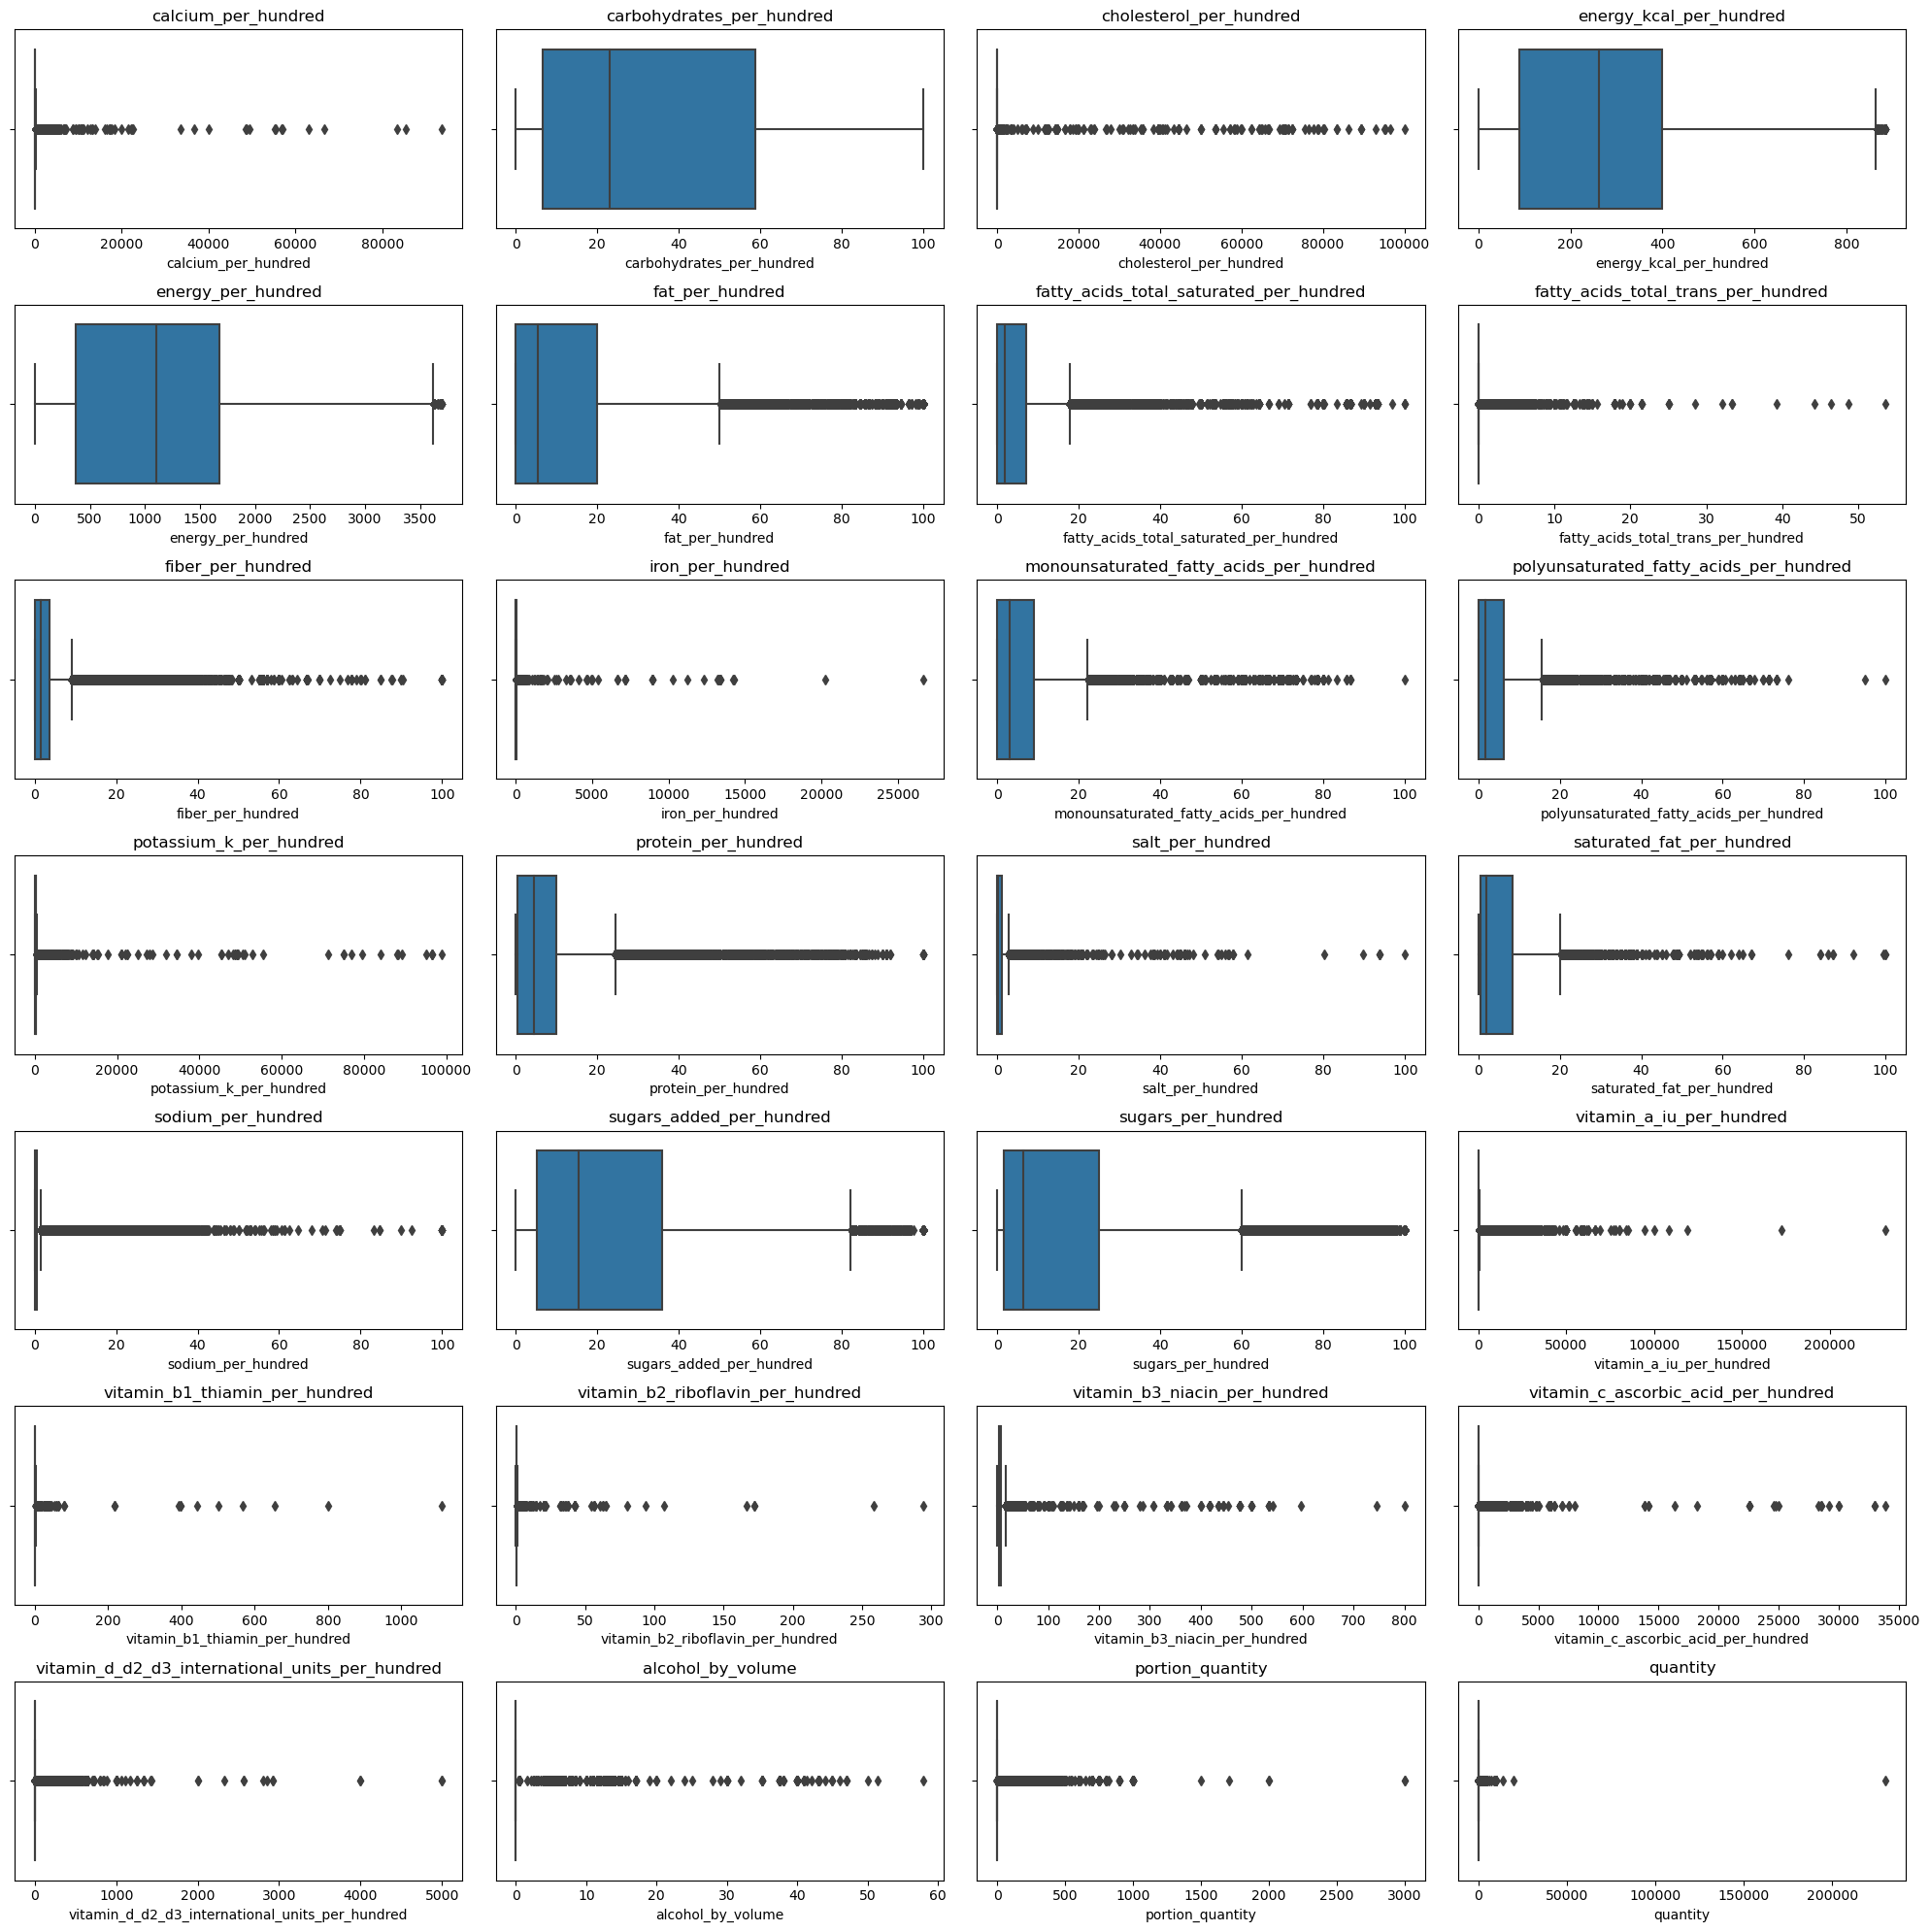

In [206]:
numerical_values_filtered = df_filtered.loc[:, df_filtered.dtypes == "float64"]
fig, axes = plt.subplots(7, 4, figsize=(20, 20))

for ax, col in zip(axes.flat, numerical_values_filtered.columns):
    sns.boxplot(x=numerical_values_filtered[col], ax=ax)
    ax.set_title(col)

plt.tight_layout()
plt.show()

The only visible outlier left is the quantity, but I will leave it for now just in case it's needed later. Since we need to save the new dataframe in a new file I think I will stop here. However, what could potientially be more interesting is to create seperate dataframes of one with full columns so that these types of plots would be better. 

6. **Saving the cleaned data as a new pickle file:**

In [208]:
df_filtered.to_pickle('OpenFood_data_analysis_cleaned.pkl')